<a href="https://colab.research.google.com/github/najeemadelakun/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing/blob/main/MSC502_M1_Fault_Tolerant_Processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# ============================================================
# STEP 1: PYTHON ENVIRONMENT AND LIBRARY SETUP
# MSC502 M1: Evidence-Driven Fault-Tolerant Processing
# ============================================================

# 1. Install required third-party libraries
!pip -q install numpy pandas matplotlib pytest hypothesis

# 2. Import standard Python libraries
import os
import sys
import json
import time
import uuid
import math
import random
import sqlite3
import logging
import platform
import statistics
import threading

from datetime import datetime, timezone
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from collections import Counter, defaultdict
from dataclasses import dataclass, asdict
from typing import Any, Dict, List, Optional, Tuple

# 3. Import third-party libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytest
import hypothesis

# 4. Display environment information
print("=" * 65)
print("MSC502 M1: PYTHON ENVIRONMENT VERIFICATION")
print("=" * 65)

print(f"Python Version       : {platform.python_version()}")
print(f"Python Platform      : {platform.platform()}")
print(f"NumPy Version        : {np.__version__}")
print(f"Pandas Version       : {pd.__version__}")
print(f"Matplotlib Version   : {plt.matplotlib.__version__}")
print(f"Pytest Version       : {pytest.__version__}")
print(f"Hypothesis Version   : {hypothesis.__version__}")

print("\nEnvironment Status   : READY")
print("Library Imports      : SUCCESSFUL")
print("=" * 65)


MSC502 M1: PYTHON ENVIRONMENT VERIFICATION
Python Version       : 3.13.18
Python Platform      : Linux-6.6.159+-x86_64-with-glibc2.39
NumPy Version        : 2.4.6
Pandas Version       : 2.2.3
Matplotlib Version   : 3.10.0
Pytest Version       : 8.4.2
Hypothesis Version   : 6.170.15

Environment Status   : READY
Library Imports      : SUCCESSFUL


In [2]:

# ============================================================
# STEP 2: PROJECT WORKSPACE AND SOURCE STRUCTURE
# MSC502 M1: Evidence-Driven Fault-Tolerant Processing
# ============================================================

from pathlib import Path

# 1. Define project workspace
PROJECT_ROOT = Path("/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing")

# 2. Define project directories
DIRECTORIES = [
    "src",
    "tests",
    "data",
    "logs",
    "results",
    "figures",
    "reports"
]

# 3. Create project directories
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

for directory in DIRECTORIES:
    (PROJECT_ROOT / directory).mkdir(exist_ok=True)

# 4. Initialise Python package
(PROJECT_ROOT / "src" / "__init__.py").touch(exist_ok=True)
(PROJECT_ROOT / "tests" / "__init__.py").touch(exist_ok=True)

# 5. Create central configuration module
config_content = '''
"""Central configuration for the MSC502 M1 processing system."""

from pathlib import Path

PROJECT_ROOT = Path(__file__).resolve().parent.parent

DATA_DIR = PROJECT_ROOT / "data"
LOG_DIR = PROJECT_ROOT / "logs"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
REPORTS_DIR = PROJECT_ROOT / "reports"

DEFAULT_WORKERS = 4
MAX_WORKERS = 16

DEFAULT_REQUEST_COUNT = 1000
TARGET_THROUGHPUT = 10000

FAILURE_RATE = 0.30
MAX_RETRIES = 3

RANDOM_SEED = 42

for directory in [
    DATA_DIR,
    LOG_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
    REPORTS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)
'''

config_path = PROJECT_ROOT / "src" / "config.py"
config_path.write_text(config_content.strip() + "\n", encoding="utf-8")

# 6. Display project structure
print("=" * 70)
print("MSC502 M1: PROJECT WORKSPACE INITIALISATION")
print("=" * 70)

print(f"\nProject Root: {PROJECT_ROOT}\n")

for path in sorted(PROJECT_ROOT.rglob("*")):
    relative_path = path.relative_to(PROJECT_ROOT)
    if path.is_dir():
        print(f"[DIR]  {relative_path}/")
    else:
        print(f"[FILE] {relative_path}")

# 7. Verify directory and configuration creation
checks = {
    "Project root created": PROJECT_ROOT.exists(),
    "Source directory created": (PROJECT_ROOT / "src").is_dir(),
    "Tests directory created": (PROJECT_ROOT / "tests").is_dir(),
    "Data directory created": (PROJECT_ROOT / "data").is_dir(),
    "Logs directory created": (PROJECT_ROOT / "logs").is_dir(),
    "Results directory created": (PROJECT_ROOT / "results").is_dir(),
    "Figures directory created": (PROJECT_ROOT / "figures").is_dir(),
    "Reports directory created": (PROJECT_ROOT / "reports").is_dir(),
    "Python package initialised": (PROJECT_ROOT / "src" / "__init__.py").exists(),
    "Configuration file created": config_path.exists()
}

print("\n" + "=" * 70)
print("PROJECT STRUCTURE VERIFICATION")
print("=" * 70)

for description, passed in checks.items():
    print(f"{description:<38}: {'PASS' if passed else 'FAIL'}")

print("-" * 70)
print(f"Verification Summary: {sum(checks.values())}/{len(checks)} checks passed")
print("=" * 70)

assert all(checks.values()), "Project structure verification failed."

# 8. Set working directory
os.chdir(PROJECT_ROOT)

print(f"\nActive Working Directory: {Path.cwd()}")


MSC502 M1: PROJECT WORKSPACE INITIALISATION

Project Root: /content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing

[DIR]  data/
[DIR]  figures/
[DIR]  logs/
[DIR]  reports/
[DIR]  results/
[DIR]  src/
[FILE] src/__init__.py
[FILE] src/config.py
[DIR]  tests/
[FILE] tests/__init__.py

PROJECT STRUCTURE VERIFICATION
Project root created                  : PASS
Source directory created              : PASS
Tests directory created               : PASS
Data directory created                : PASS
Logs directory created                : PASS
Results directory created             : PASS
Figures directory created             : PASS
Reports directory created             : PASS
Python package initialised            : PASS
Configuration file created            : PASS
----------------------------------------------------------------------
Verification Summary: 10/10 checks passed

Active Working Directory: /content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing


In [3]:

# ============================================================
# STEP 3: CORE PROCESSING ARCHITECTURE
# Request Models, Validation, Processing Engine and Telemetry
# ============================================================

import sys
sys.path.insert(0, str(PROJECT_ROOT))

# ------------------------------------------------------------
# 3.1 REQUEST AND RESPONSE MODELS
# ------------------------------------------------------------

models_code = '''
"""Request and response data models."""

from dataclasses import dataclass, field
from datetime import datetime, timezone
from typing import Any, Optional
import uuid


@dataclass
class ProcessingRequest:
    operation: str
    values: list
    request_id: str = field(default_factory=lambda: str(uuid.uuid4()))
    trace_id: str = field(default_factory=lambda: str(uuid.uuid4()))
    created_at: str = field(
        default_factory=lambda: datetime.now(timezone.utc).isoformat()
    )


@dataclass
class ProcessingResponse:
    request_id: str
    trace_id: str
    status_code: int
    status: str
    result: Optional[float]
    latency_us: float
    timestamp: str
    error: Optional[str] = None
'''

(PROJECT_ROOT / "src" / "models.py").write_text(
    models_code.strip() + "\n", encoding="utf-8"
)

# ------------------------------------------------------------
# 3.2 INPUT VALIDATION
# ------------------------------------------------------------

validator_code = '''
"""Input validation for processing requests."""

import math


SUPPORTED_OPERATIONS = {
    "sum",
    "multiply",
    "minimum",
    "maximum",
    "mean"
}


def validate_request(request):
    if request.operation not in SUPPORTED_OPERATIONS:
        raise ValueError(
            f"Unsupported operation: {request.operation}"
        )

    if not isinstance(request.values, list) or not request.values:
        raise ValueError("Values must be a non-empty list.")

    for value in request.values:
        if isinstance(value, bool) or not isinstance(value, (int, float)):
            raise ValueError("All values must be numeric.")

        if not math.isfinite(value):
            raise ValueError("Values must be finite numbers.")

    return True
'''

(PROJECT_ROOT / "src" / "validator.py").write_text(
    validator_code.strip() + "\n", encoding="utf-8"
)

# ------------------------------------------------------------
# 3.3 DETERMINISTIC PROCESSING ENGINE
# ------------------------------------------------------------

engine_code = '''
"""Deterministic numerical processing engine."""

import math


class ProcessingEngine:

    @staticmethod
    def execute(operation, values):

        if operation == "sum":
            result = math.fsum(values)

        elif operation == "multiply":
            result = math.prod(values)

        elif operation == "minimum":
            result = min(values)

        elif operation == "maximum":
            result = max(values)

        elif operation == "mean":
            result = math.fsum(values) / len(values)

        else:
            raise ValueError(f"Unsupported operation: {operation}")

        if not math.isfinite(result):
            raise ArithmeticError("Result is not finite.")

        return float(result)
'''

(PROJECT_ROOT / "src" / "engine.py").write_text(
    engine_code.strip() + "\n", encoding="utf-8"
)

# ------------------------------------------------------------
# 3.4 STRUCTURED TELEMETRY
# ------------------------------------------------------------

telemetry_code = '''
"""Thread-safe structured JSON telemetry."""

import json
import logging
import threading

from datetime import datetime, timezone
from pathlib import Path


class TelemetryLogger:

    def __init__(self, log_directory):
        self.log_directory = Path(log_directory)
        self.log_directory.mkdir(parents=True, exist_ok=True)

        self.log_file = self.log_directory / "telemetry.jsonl"
        self.lock = threading.Lock()

    def record(
        self,
        request_id,
        trace_id,
        status_code,
        status,
        latency_us,
        message=None,
        error=None
    ):

        entry = {
            "timestamp": datetime.now(timezone.utc).isoformat(),
            "level": "ERROR" if error else "INFO",
            "message": message or "Request processed",
            "request_id": request_id,
            "trace_id": trace_id,
            "status_code": status_code,
            "status": status,
            "latency_us": round(float(latency_us), 3),
            "error": error
        }

        with self.lock:
            with self.log_file.open("a", encoding="utf-8") as file:
                file.write(json.dumps(entry, allow_nan=False) + "\\n")

        return entry
'''

(PROJECT_ROOT / "src" / "telemetry.py").write_text(
    telemetry_code.strip() + "\n", encoding="utf-8"
)

# ------------------------------------------------------------
# 3.5 PROCESSING SERVICE
# ------------------------------------------------------------

processor_code = '''
"""Integrated request processing service."""

import time
import math

from datetime import datetime, timezone

from src.models import ProcessingResponse
from src.validator import validate_request
from src.engine import ProcessingEngine
from src.telemetry import TelemetryLogger


class ProcessingService:

    def __init__(self, log_directory):
        self.engine = ProcessingEngine()
        self.telemetry = TelemetryLogger(log_directory)

    def process(self, request):

        start_time = time.perf_counter_ns()

        try:
            validate_request(request)

            result = self.engine.execute(
                request.operation,
                request.values
            )

            status_code = 200
            status = "SUCCESS"
            error = None

        except (ValueError, ArithmeticError) as exception:
            result = None
            status_code = 400 if isinstance(exception, ValueError) else 422
            status = "FAILED"
            error = str(exception)

        except Exception as exception:
            result = None
            status_code = 500
            status = "ERROR"
            error = str(exception)

        latency_us = (time.perf_counter_ns() - start_time) / 1000

        response = ProcessingResponse(
            request_id=request.request_id,
            trace_id=request.trace_id,
            status_code=status_code,
            status=status,
            result=result,
            latency_us=latency_us,
            timestamp=datetime.now(timezone.utc).isoformat(),
            error=error
        )

        self.telemetry.record(
            request_id=request.request_id,
            trace_id=request.trace_id,
            status_code=status_code,
            status=status,
            latency_us=latency_us,
            error=error
        )

        return response
'''

(PROJECT_ROOT / "src" / "processor.py").write_text(
    processor_code.strip() + "\n", encoding="utf-8"
)

# ------------------------------------------------------------
# 3.6 IMPORT AND FUNCTIONAL VERIFICATION
# ------------------------------------------------------------

from src.models import ProcessingRequest
from src.processor import ProcessingService

service = ProcessingService(PROJECT_ROOT / "logs")

test_cases = [
    ("sum", [10, 20, 30, 40], 100.0),
    ("multiply", [2, 3, 4], 24.0),
    ("minimum", [8, 3, 12, 5], 3.0),
    ("maximum", [8, 3, 12, 5], 12.0),
    ("mean", [10, 20, 30, 40], 25.0)
]

print("=" * 75)
print("MSC502 M1: CORE PROCESSING FUNCTIONAL VERIFICATION")
print("=" * 75)

functional_results = []

for operation, values, expected in test_cases:

    request = ProcessingRequest(
        operation=operation,
        values=values
    )

    response = service.process(request)

    passed = (
        response.status_code == 200
        and math.isclose(response.result, expected, rel_tol=1e-12)
    )

    functional_results.append(passed)

    print(f"\nOperation       : {operation}")
    print(f"Input Values    : {values}")
    print(f"Expected Result : {expected}")
    print(f"Actual Result   : {response.result}")
    print(f"Status Code     : {response.status_code}")
    print(f"Latency         : {response.latency_us:.3f} µs")
    print(f"Verification    : {'PASS' if passed else 'FAIL'}")

# ------------------------------------------------------------
# 3.7 INVALID REQUEST VERIFICATION
# ------------------------------------------------------------

invalid_requests = [
    ProcessingRequest("division", [10, 2]),
    ProcessingRequest("sum", []),
    ProcessingRequest("sum", [10, "invalid"]),
    ProcessingRequest("mean", [float("nan"), 5])
]

invalid_results = []

print("\n" + "=" * 75)
print("INVALID REQUEST HANDLING")
print("=" * 75)

for request in invalid_requests:

    response = service.process(request)

    passed = (
        response.status_code in (400, 422)
        and response.result is None
        and response.error is not None
    )

    invalid_results.append(passed)

    print(
        f"Operation: {request.operation:<10} "
        f"Status: {response.status_code:<3} "
        f"Verification: {'PASS' if passed else 'FAIL'}"
    )

# ------------------------------------------------------------
# 3.8 FINAL VERIFICATION
# ------------------------------------------------------------

all_results = functional_results + invalid_results

print("\n" + "=" * 75)
print("CORE PROCESSING VERIFICATION SUMMARY")
print("=" * 75)

print(f"Valid processing tests : {sum(functional_results)}/{len(functional_results)}")
print(f"Invalid input tests    : {sum(invalid_results)}/{len(invalid_results)}")
print(f"Total checks passed    : {sum(all_results)}/{len(all_results)}")

print(
    "Overall Status        :",
    "PASS" if all(all_results) else "FAIL"
)

print("=" * 75)

assert all(all_results), "Core processing verification failed."

# Confirm telemetry file creation
telemetry_file = PROJECT_ROOT / "logs" / "telemetry.jsonl"

print(f"\nTelemetry File Created: {telemetry_file.exists()}")
print(f"Telemetry Records     : {len(telemetry_file.read_text().splitlines())}")


MSC502 M1: CORE PROCESSING FUNCTIONAL VERIFICATION

Operation       : sum
Input Values    : [10, 20, 30, 40]
Expected Result : 100.0
Actual Result   : 100.0
Status Code     : 200
Latency         : 9.380 µs
Verification    : PASS

Operation       : multiply
Input Values    : [2, 3, 4]
Expected Result : 24.0
Actual Result   : 24.0
Status Code     : 200
Latency         : 6.660 µs
Verification    : PASS

Operation       : minimum
Input Values    : [8, 3, 12, 5]
Expected Result : 3.0
Actual Result   : 3.0
Status Code     : 200
Latency         : 4.000 µs
Verification    : PASS

Operation       : maximum
Input Values    : [8, 3, 12, 5]
Expected Result : 12.0
Actual Result   : 12.0
Status Code     : 200
Latency         : 3.370 µs
Verification    : PASS

Operation       : mean
Input Values    : [10, 20, 30, 40]
Expected Result : 25.0
Actual Result   : 25.0
Status Code     : 200
Latency         : 3.890 µs
Verification    : PASS

INVALID REQUEST HANDLING
Operation: division   Status: 400 Verifica

In [4]:

# ============================================================
# STEP 4: CONCURRENT PROCESSING AND THREAD-SAFETY VALIDATION
# ============================================================

import sys
import time
import uuid
import math
import numpy as np
import pandas as pd

from concurrent.futures import ThreadPoolExecutor

sys.path.insert(0, str(PROJECT_ROOT))

# ------------------------------------------------------------
# 4.1 IMPLEMENT CONCURRENT PROCESSOR
# ------------------------------------------------------------

concurrency_code = '''
"""Configurable concurrent request processor."""

from concurrent.futures import ThreadPoolExecutor


class ConcurrentProcessor:

    def __init__(self, max_workers, processing_service):
        if max_workers < 1:
            raise ValueError("max_workers must be at least 1.")

        self.max_workers = max_workers
        self.processing_service = processing_service

    def process_batch(self, requests):

        with ThreadPoolExecutor(
            max_workers=self.max_workers
        ) as executor:

            responses = list(
                executor.map(
                    self.processing_service.process,
                    requests
                )
            )

        return responses
'''

(PROJECT_ROOT / "src" / "concurrency.py").write_text(
    concurrency_code.strip() + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 4.2 IMPORT CONCURRENT PROCESSOR
# ------------------------------------------------------------

from src.concurrency import ConcurrentProcessor
from src.models import ProcessingRequest
from src.processor import ProcessingService

# ------------------------------------------------------------
# 4.3 GENERATE A REPRODUCIBLE WORKLOAD
# ------------------------------------------------------------

RANDOM_SEED = 42
REQUEST_COUNT = 1000

rng = np.random.default_rng(RANDOM_SEED)

def generate_requests(count):

    operations = ["sum", "multiply", "minimum", "maximum", "mean"]
    requests = []

    for _ in range(count):

        values = rng.integers(1, 100, size=10).tolist()
        operation = operations[rng.integers(0, len(operations))]

        requests.append(
            ProcessingRequest(
                operation=operation,
                values=values
            )
        )

    return requests


# Generate one fixed workload for all worker configurations
workload = generate_requests(REQUEST_COUNT)

print("=" * 75)
print("MSC502 M1: CONCURRENT PROCESSING EXPERIMENT")
print("=" * 75)

print(f"Total Requests       : {len(workload)}")
print(f"Random Seed          : {RANDOM_SEED}")
print(f"Worker Configurations: 1, 2, 4, 8")

# ------------------------------------------------------------
# 4.4 EXECUTE WORKLOAD UNDER DIFFERENT WORKER COUNTS
# ------------------------------------------------------------

worker_counts = [1, 2, 4, 8]

benchmark_results = []
benchmark_responses = {}

for workers in worker_counts:

    # Use a separate telemetry file for each configuration
    worker_log_dir = PROJECT_ROOT / "logs" / f"workers_{workers}"

    service = ProcessingService(worker_log_dir)

    processor = ConcurrentProcessor(
        max_workers=workers,
        processing_service=service
    )

    start_time = time.perf_counter()

    responses = processor.process_batch(workload)

    elapsed_time = time.perf_counter() - start_time

    benchmark_responses[workers] = responses

    latencies = np.array(
        [response.latency_us for response in responses],
        dtype=float
    )

    successful = sum(
        response.status_code == 200 for response in responses
    )

    failed = len(responses) - successful

    throughput = len(responses) / elapsed_time

    result = {
        "workers": workers,
        "requests_submitted": len(workload),
        "responses_received": len(responses),
        "successful": successful,
        "failed": failed,
        "elapsed_seconds": elapsed_time,
        "throughput_ops_sec": throughput,
        "mean_latency_us": float(np.mean(latencies)),
        "p50_us": float(np.percentile(latencies, 50)),
        "p90_us": float(np.percentile(latencies, 90)),
        "p99_us": float(np.percentile(latencies, 99)),
        "p99_9_us": float(np.percentile(latencies, 99.9))
    }

    benchmark_results.append(result)

# ------------------------------------------------------------
# 4.5 DISPLAY BENCHMARK RESULTS
# ------------------------------------------------------------

benchmark_df = pd.DataFrame(benchmark_results)

print("\n" + "=" * 75)
print("CONCURRENT PROCESSING BENCHMARK RESULTS")
print("=" * 75)

display(
    benchmark_df.round(3)
)

# ------------------------------------------------------------
# 4.6 VERIFY REQUEST COMPLETENESS AND UNIQUENESS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("REQUEST COMPLETENESS AND THREAD-SAFETY CHECKS")
print("=" * 75)

verification_results = []

for workers in worker_counts:

    responses = benchmark_responses[workers]

    submitted_ids = [request.request_id for request in workload]
    returned_ids = [response.request_id for response in responses]

    submitted_trace_ids = [request.trace_id for request in workload]
    returned_trace_ids = [response.trace_id for response in responses]

    checks = {
        "All responses received":
            len(responses) == REQUEST_COUNT,

        "No missing request IDs":
            set(returned_ids) == set(submitted_ids),

        "No duplicate response IDs":
            len(returned_ids) == len(set(returned_ids)),

        "Trace IDs preserved":
            returned_trace_ids == submitted_trace_ids,

        "Response order preserved":
            returned_ids == submitted_ids,

        "All requests successful":
            all(response.status_code == 200 for response in responses),

        "All results finite":
            all(
                response.result is not None
                and math.isfinite(response.result)
                for response in responses
            )
    }

    passed = all(checks.values())

    verification_results.append({
        "workers": workers,
        "checks_passed": sum(checks.values()),
        "total_checks": len(checks),
        "status": "PASS" if passed else "FAIL"
    })

    print(f"\nWorker Configuration: {workers}")

    for description, result in checks.items():
        print(
            f"{description:<32}: "
            f"{'PASS' if result else 'FAIL'}"
        )

verification_df = pd.DataFrame(verification_results)

# ------------------------------------------------------------
# 4.7 SAVE BENCHMARK DATA
# ------------------------------------------------------------

benchmark_file = PROJECT_ROOT / "results" / "concurrency_benchmark.csv"
verification_file = PROJECT_ROOT / "results" / "concurrency_verification.csv"

benchmark_df.to_csv(benchmark_file, index=False)
verification_df.to_csv(verification_file, index=False)

# ------------------------------------------------------------
# 4.8 FINAL ACCEPTANCE SUMMARY
# ------------------------------------------------------------

all_passed = all(
    item["status"] == "PASS"
    for item in verification_results
)

print("\n" + "=" * 75)
print("STEP 4 ACCEPTANCE SUMMARY")
print("=" * 75)

print(f"Workload Size          : {REQUEST_COUNT}")
print(f"Worker Configurations  : {len(worker_counts)}")
print(f"Total Requests Tested  : {REQUEST_COUNT * len(worker_counts)}")
print(f"Verification Status    : {'PASS' if all_passed else 'FAIL'}")
print(f"Benchmark CSV          : {benchmark_file}")
print(f"Verification CSV       : {verification_file}")

print("=" * 75)

assert all_passed, "Concurrent processing verification failed."


MSC502 M1: CONCURRENT PROCESSING EXPERIMENT
Total Requests       : 1000
Random Seed          : 42
Worker Configurations: 1, 2, 4, 8

CONCURRENT PROCESSING BENCHMARK RESULTS


,workers,requests_submitted,responses_received,successful,failed,elapsed_seconds,throughput_ops_sec,mean_latency_us,p50_us,p90_us,p99_us,p99_9_us
0,1,1000,1000,1000,0,0.199,5033.091,5.387,4.950,6.432,14.100,37.357
1,2,1000,1000,1000,0,0.136,7357.941,9.521,5.020,6.031,21.032,72.163
2,4,1000,1000,1000,0,0.113,8865.758,5.609,5.340,6.161,14.509,40.508
3,8,1000,1000,1000,0,0.156,6426.845,10.373,5.309,6.300,14.628,1455.468



REQUEST COMPLETENESS AND THREAD-SAFETY CHECKS

Worker Configuration: 1
All responses received          : PASS
No missing request IDs          : PASS
No duplicate response IDs       : PASS
Trace IDs preserved             : PASS
Response order preserved        : PASS
All requests successful         : PASS
All results finite              : PASS

Worker Configuration: 2
All responses received          : PASS
No missing request IDs          : PASS
No duplicate response IDs       : PASS
Trace IDs preserved             : PASS
Response order preserved        : PASS
All requests successful         : PASS
All results finite              : PASS

Worker Configuration: 4
All responses received          : PASS
No missing request IDs          : PASS
No duplicate response IDs       : PASS
Trace IDs preserved             : PASS
Response order preserved        : PASS
All requests successful         : PASS
All results finite              : PASS

Worker Configuration: 8
All responses received          : 

In [5]:

# ============================================================
# STEP 5: SIMULATED FAILURE INJECTION AND AUTOMATIC RETRY
# ============================================================

import sys
import time
import hashlib
import threading
import numpy as np
import pandas as pd

sys.path.insert(0, str(PROJECT_ROOT))

from src.models import ProcessingRequest, ProcessingResponse
from src.processor import ProcessingService

# ------------------------------------------------------------
# 5.1 IMPLEMENT DETERMINISTIC FAILURE INJECTOR
# ------------------------------------------------------------

fault_injector_code = '''
"""Deterministic, thread-safe transient failure injector."""

import hashlib
import threading


class FaultInjector:

    def __init__(self, failure_rate=0.30, seed=42):

        if not 0 <= failure_rate <= 1:
            raise ValueError("failure_rate must be between 0 and 1.")

        self.failure_rate = failure_rate
        self.seed = seed
        self.lock = threading.Lock()

        self.injection_checks = 0
        self.injected_failures = 0

    def should_fail(self, request_id, attempt):

        token = f"{self.seed}:{request_id}:{attempt}"
        digest = hashlib.sha256(token.encode()).hexdigest()

        value = int(digest[:16], 16) / (16 ** 16)

        failed = value < self.failure_rate

        with self.lock:
            self.injection_checks += 1

            if failed:
                self.injected_failures += 1

        return failed

    def summary(self):

        with self.lock:
            checks = self.injection_checks
            failures = self.injected_failures

        return {
            "injection_checks": checks,
            "injected_failures": failures,
            "observed_failure_rate": (
                failures / checks if checks else 0.0
            )
        }
'''

(PROJECT_ROOT / "src" / "fault_injector.py").write_text(
    fault_injector_code.strip() + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 5.2 IMPLEMENT FAULT-TOLERANT PROCESSOR
# ------------------------------------------------------------

fault_tolerance_code = '''
"""Automatic retry and recovery for transient failures."""

import time

from datetime import datetime, timezone

from src.models import ProcessingResponse


class FaultTolerantProcessor:

    def __init__(
        self,
        processing_service,
        fault_injector,
        max_retries=8
    ):

        if max_retries < 0:
            raise ValueError("max_retries cannot be negative.")

        self.processing_service = processing_service
        self.fault_injector = fault_injector
        self.max_retries = max_retries

    def process(self, request):

        start_time = time.perf_counter_ns()

        for attempt in range(self.max_retries + 1):

            if self.fault_injector.should_fail(
                request.request_id,
                attempt
            ):
                continue

            response = self.processing_service.process(request)
            response_attempts = attempt + 1

            return response, response_attempts

        latency_us = (
            time.perf_counter_ns() - start_time
        ) / 1000

        error = (
            f"Transient failures persisted after "
            f"{self.max_retries + 1} attempts."
        )

        response = ProcessingResponse(
            request_id=request.request_id,
            trace_id=request.trace_id,
            status_code=503,
            status="RETRY_EXHAUSTED",
            result=None,
            latency_us=latency_us,
            timestamp=datetime.now(timezone.utc).isoformat(),
            error=error
        )

        self.processing_service.telemetry.record(
            request_id=request.request_id,
            trace_id=request.trace_id,
            status_code=503,
            status="RETRY_EXHAUSTED",
            latency_us=latency_us,
            error=error
        )

        return response, self.max_retries + 1
'''

(PROJECT_ROOT / "src" / "fault_tolerance.py").write_text(
    fault_tolerance_code.strip() + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 5.3 IMPORT FAULT-TOLERANCE COMPONENTS
# ------------------------------------------------------------

from src.fault_injector import FaultInjector
from src.fault_tolerance import FaultTolerantProcessor
from src.concurrency import ConcurrentProcessor

# ------------------------------------------------------------
# 5.4 GENERATE A REPRODUCIBLE FAILURE-TEST WORKLOAD
# ------------------------------------------------------------

FAILURE_REQUEST_COUNT = 1000
FAILURE_RATE = 0.30
MAX_RETRIES = 8
FAILURE_SEED = 42

rng_failure = np.random.default_rng(FAILURE_SEED)

operations = ["sum", "multiply", "minimum", "maximum", "mean"]

failure_workload = []

for _ in range(FAILURE_REQUEST_COUNT):

    values = rng_failure.integers(1, 100, size=10).tolist()
    operation = operations[
        rng_failure.integers(0, len(operations))
    ]

    failure_workload.append(
        ProcessingRequest(
            operation=operation,
            values=values
        )
    )

# ------------------------------------------------------------
# 5.5 EXECUTE FAILURE-INJECTION EXPERIMENT
# ------------------------------------------------------------

failure_service = ProcessingService(
    PROJECT_ROOT / "logs" / "failure_injection"
)

fault_injector = FaultInjector(
    failure_rate=FAILURE_RATE,
    seed=FAILURE_SEED
)

fault_tolerant_processor = FaultTolerantProcessor(
    processing_service=failure_service,
    fault_injector=fault_injector,
    max_retries=MAX_RETRIES
)

# Adapter returns the response and attempt count together.
def execute_fault_tolerant(request):
    return fault_tolerant_processor.process(request)

failure_concurrency = ThreadPoolExecutor(max_workers=4)

start_time = time.perf_counter()

try:
    failure_results = list(
        failure_concurrency.map(
            execute_fault_tolerant,
            failure_workload
        )
    )
finally:
    failure_concurrency.shutdown(wait=True)

failure_elapsed = time.perf_counter() - start_time

failure_responses = [item[0] for item in failure_results]
attempt_counts = [item[1] for item in failure_results]

# ------------------------------------------------------------
# 5.6 COMPUTE FAILURE AND RECOVERY METRICS
# ------------------------------------------------------------

fault_summary = fault_injector.summary()

successful_requests = sum(
    response.status_code == 200
    for response in failure_responses
)

exhausted_requests = sum(
    response.status_code == 503
    for response in failure_responses
)

other_failed_requests = (
    len(failure_responses)
    - successful_requests
    - exhausted_requests
)

total_attempts = sum(attempt_counts)

recovered_requests = sum(
    attempts > 1 and response.status_code == 200
    for response, attempts in failure_results
)

average_attempts = float(np.mean(attempt_counts))

observed_rate = fault_summary["observed_failure_rate"]

failure_throughput = (
    len(failure_responses) / failure_elapsed
    if failure_elapsed > 0 else 0
)

# ------------------------------------------------------------
# 5.7 REQUEST ACCOUNTING AND INTEGRITY CHECKS
# ------------------------------------------------------------

submitted_ids = [
    request.request_id for request in failure_workload
]

returned_ids = [
    response.request_id for response in failure_responses
]

checks = {
    "All submitted requests returned":
        len(failure_responses) == FAILURE_REQUEST_COUNT,

    "No request IDs missing":
        set(submitted_ids) == set(returned_ids),

    "No duplicate response IDs":
        len(returned_ids) == len(set(returned_ids)),

    "All trace IDs preserved":
        [
            response.trace_id for response in failure_responses
        ] == [
            request.trace_id for request in failure_workload
        ],

    "All requests accounted for":
        successful_requests
        + exhausted_requests
        + other_failed_requests
        == FAILURE_REQUEST_COUNT,

    "All requests received valid attempt counts":
        all(1 <= count <= MAX_RETRIES + 1 for count in attempt_counts),

    "No unhandled exceptions":
        len(failure_results) == FAILURE_REQUEST_COUNT,

    "Failure injection was exercised":
        fault_summary["injected_failures"] > 0
}

# ------------------------------------------------------------
# 5.8 DISPLAY EXPERIMENT RESULTS
# ------------------------------------------------------------

print("=" * 75)
print("MSC502 M1: FAILURE INJECTION AND RECOVERY RESULTS")
print("=" * 75)

print(f"Requests Submitted       : {FAILURE_REQUEST_COUNT}")
print(f"Target Failure Rate      : {FAILURE_RATE:.2%}")
print(f"Observed Failure Rate    : {observed_rate:.2%}")
print(f"Injection Checks         : {fault_summary['injection_checks']}")
print(f"Injected Failures        : {fault_summary['injected_failures']}")
print(f"Total Processing Attempts: {total_attempts}")
print(f"Maximum Attempts/Request: {MAX_RETRIES + 1}")
print(f"Average Attempts/Request : {average_attempts:.3f}")

print("\n" + "-" * 75)
print("REQUEST OUTCOMES")
print("-" * 75)

print(f"Successful Requests      : {successful_requests}")
print(f"Recovered Requests       : {recovered_requests}")
print(f"Retry-Exhausted Requests : {exhausted_requests}")
print(f"Other Failed Requests    : {other_failed_requests}")
print(f"Unaccounted Requests     : {FAILURE_REQUEST_COUNT - len(failure_responses)}")

print("\n" + "-" * 75)
print("PERFORMANCE MEASUREMENTS")
print("-" * 75)

print(f"Elapsed Time             : {failure_elapsed:.6f} seconds")
print(f"Achieved Throughput      : {failure_throughput:.2f} requests/second")

print("\n" + "-" * 75)
print("ACCEPTANCE CHECKS")
print("-" * 75)

for description, passed in checks.items():
    print(f"{description:<42}: {'PASS' if passed else 'FAIL'}")

# ------------------------------------------------------------
# 5.9 SAVE FAILURE-TEST RESULTS
# ------------------------------------------------------------

failure_metrics = {
    "requests_submitted": FAILURE_REQUEST_COUNT,
    "target_failure_rate": FAILURE_RATE,
    "observed_failure_rate": observed_rate,
    "injection_checks": fault_summary["injection_checks"],
    "injected_failures": fault_summary["injected_failures"],
    "total_attempts": total_attempts,
    "average_attempts": average_attempts,
    "successful_requests": successful_requests,
    "recovered_requests": recovered_requests,
    "retry_exhausted_requests": exhausted_requests,
    "other_failed_requests": other_failed_requests,
    "elapsed_seconds": failure_elapsed,
    "throughput_requests_sec": failure_throughput,
    "max_retries": MAX_RETRIES,
    "unaccounted_requests": FAILURE_REQUEST_COUNT - len(failure_responses)
}

failure_metrics_file = (
    PROJECT_ROOT / "results" / "failure_injection_metrics.json"
)

failure_metrics_file.write_text(
    json.dumps(failure_metrics, indent=4),
    encoding="utf-8"
)

failure_acceptance_file = (
    PROJECT_ROOT / "results" / "failure_injection_acceptance.csv"
)

pd.DataFrame([
    {
        "check": description,
        "result": "PASS" if passed else "FAIL"
    }
    for description, passed in checks.items()
]).to_csv(failure_acceptance_file, index=False)

# ------------------------------------------------------------
# 5.10 FINAL ACCEPTANCE SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 5 FINAL ACCEPTANCE SUMMARY")
print("=" * 75)

print(f"Checks Passed             : {sum(checks.values())}/{len(checks)}")
print(f"Verification Status       : {'PASS' if all(checks.values()) else 'FAIL'}")
print(f"Failure Metrics File      : {failure_metrics_file}")
print(f"Acceptance Results File   : {failure_acceptance_file}")

print("=" * 75)

assert all(checks.values()), "Failure injection verification failed."


MSC502 M1: FAILURE INJECTION AND RECOVERY RESULTS
Requests Submitted       : 1000
Target Failure Rate      : 30.00%
Observed Failure Rate    : 28.93%
Injection Checks         : 1407
Injected Failures        : 407
Total Processing Attempts: 1407
Maximum Attempts/Request: 9
Average Attempts/Request : 1.407

---------------------------------------------------------------------------
REQUEST OUTCOMES
---------------------------------------------------------------------------
Successful Requests      : 1000
Recovered Requests       : 287
Retry-Exhausted Requests : 0
Other Failed Requests    : 0
Unaccounted Requests     : 0

---------------------------------------------------------------------------
PERFORMANCE MEASUREMENTS
---------------------------------------------------------------------------
Elapsed Time             : 0.088334 seconds
Achieved Throughput      : 11320.66 requests/second

---------------------------------------------------------------------------
ACCEPTANCE CHECKS
-----

In [6]:

# ============================================================
# STEP 6: DURABLE TRANSACTION MANAGEMENT AND RECOVERY
# ============================================================

import sys
import json
import sqlite3
import time
import uuid
import pandas as pd

from pathlib import Path
from datetime import datetime, timezone

sys.path.insert(0, str(PROJECT_ROOT))

# ------------------------------------------------------------
# 6.1 IMPLEMENT SQLITE TRANSACTION JOURNAL
# ------------------------------------------------------------

transaction_code = '''
"""Durable SQLite transaction journal."""

import json
import sqlite3
import threading

from pathlib import Path
from datetime import datetime, timezone


class TransactionJournal:

    def __init__(self, database_path):

        self.database_path = Path(database_path)
        self.database_path.parent.mkdir(parents=True, exist_ok=True)

        self.lock = threading.RLock()

        self._initialise_database()

    def _connect(self):

        connection = sqlite3.connect(
            str(self.database_path),
            timeout=30
        )

        connection.row_factory = sqlite3.Row
        connection.execute("PRAGMA busy_timeout = 30000")

        return connection

    def _initialise_database(self):

        with self._connect() as connection:

            connection.execute("PRAGMA journal_mode = WAL")
            connection.execute("PRAGMA synchronous = FULL")

            connection.execute("""
                CREATE TABLE IF NOT EXISTS transactions (
                    request_id TEXT PRIMARY KEY,
                    trace_id TEXT NOT NULL,
                    operation TEXT NOT NULL,
                    values_json TEXT NOT NULL,
                    status TEXT NOT NULL,
                    response_json TEXT,
                    attempts INTEGER NOT NULL DEFAULT 0,
                    created_at TEXT NOT NULL,
                    updated_at TEXT NOT NULL
                )
            """)

            connection.commit()

    def register_request(self, request):

        timestamp = datetime.now(timezone.utc).isoformat()

        with self.lock:
            with self._connect() as connection:

                cursor = connection.execute("""
                    INSERT OR IGNORE INTO transactions (
                        request_id,
                        trace_id,
                        operation,
                        values_json,
                        status,
                        response_json,
                        attempts,
                        created_at,
                        updated_at
                    )
                    VALUES (?, ?, ?, ?, 'PENDING', NULL, 0, ?, ?)
                """, (
                    request.request_id,
                    request.trace_id,
                    request.operation,
                    json.dumps(request.values, allow_nan=False),
                    timestamp,
                    timestamp
                ))

                connection.commit()

                return cursor.rowcount == 1

    def commit_response(self, response, attempts=1):

        timestamp = datetime.now(timezone.utc).isoformat()

        response_data = {
            "request_id": response.request_id,
            "trace_id": response.trace_id,
            "status_code": response.status_code,
            "status": response.status,
            "result": response.result,
            "latency_us": response.latency_us,
            "timestamp": response.timestamp,
            "error": response.error
        }

        with self.lock:
            with self._connect() as connection:

                cursor = connection.execute("""
                    UPDATE transactions
                    SET status = ?,
                        response_json = ?,
                        attempts = ?,
                        updated_at = ?
                    WHERE request_id = ?
                """, (
                    "COMPLETED" if response.status_code == 200 else "FAILED",
                    json.dumps(response_data, allow_nan=False),
                    attempts,
                    timestamp,
                    response.request_id
                ))

                connection.commit()

                if cursor.rowcount != 1:
                    raise KeyError(
                        f"Unknown request ID: {response.request_id}"
                    )

    def get_request(self, request_id):

        with self._connect() as connection:

            row = connection.execute("""
                SELECT * FROM transactions
                WHERE request_id = ?
            """, (request_id,)).fetchone()

        return dict(row) if row else None

    def pending_requests(self):

        with self._connect() as connection:

            rows = connection.execute("""
                SELECT * FROM transactions
                WHERE status = 'PENDING'
                ORDER BY created_at
            """).fetchall()

        return [dict(row) for row in rows]

    def total_requests(self):

        with self._connect() as connection:

            row = connection.execute("""
                SELECT COUNT(*) AS total
                FROM transactions
            """).fetchone()

        return row["total"]

    def summary(self):

        with self._connect() as connection:

            rows = connection.execute("""
                SELECT status, COUNT(*) AS total
                FROM transactions
                GROUP BY status
            """).fetchall()

        result = {
            "total_requests": self.total_requests(),
            "completed": 0,
            "failed": 0,
            "pending": 0
        }

        for row in rows:
            result[row["status"].lower()] = row["total"]

        return result

    def recover_pending(self, processing_service):

        pending = self.pending_requests()
        recovered = 0
        failed = 0

        from src.models import ProcessingRequest

        for item in pending:

            request = ProcessingRequest(
                operation=item["operation"],
                values=json.loads(item["values_json"]),
                request_id=item["request_id"],
                trace_id=item["trace_id"]
            )

            response = processing_service.process(request)

            self.commit_response(response, attempts=1)

            if response.status_code == 200:
                recovered += 1
            else:
                failed += 1

        return {
            "recovered": recovered,
            "failed": failed,
            "remaining": len(self.pending_requests())
        }
'''

(PROJECT_ROOT / "src" / "transaction_manager.py").write_text(
    transaction_code.strip() + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 6.2 INITIALISE DURABLE JOURNAL
# ------------------------------------------------------------

from src.transaction_manager import TransactionJournal
from src.models import ProcessingRequest
from src.processor import ProcessingService

DATABASE_PATH = PROJECT_ROOT / "data" / "transactions.db"

journal = TransactionJournal(DATABASE_PATH)

print("=" * 75)
print("MSC502 M1: DURABLE TRANSACTION JOURNAL")
print("=" * 75)

print(f"Database Location : {DATABASE_PATH}")
print(f"Database Created  : {DATABASE_PATH.exists()}")
print(f"Initial Summary   : {journal.summary()}")

# ------------------------------------------------------------
# 6.3 TEST REQUEST REGISTRATION AND DUPLICATE PREVENTION
# ------------------------------------------------------------

test_request = ProcessingRequest(
    operation="sum",
    values=[10, 20, 30, 40]
)

first_registration = journal.register_request(test_request)
duplicate_registration = journal.register_request(test_request)

registration_checks = {
    "First registration accepted": first_registration is True,
    "Duplicate registration rejected": duplicate_registration is False,
    "Only one transaction stored": journal.total_requests() == 1
}

print("\n" + "=" * 75)
print("REQUEST REGISTRATION AND IDEMPOTENCY")
print("=" * 75)

for description, passed in registration_checks.items():
    print(f"{description:<40}: {'PASS' if passed else 'FAIL'}")

# ------------------------------------------------------------
# 6.4 PROCESS AND COMMIT A REGISTERED REQUEST
# ------------------------------------------------------------

transaction_service = ProcessingService(
    PROJECT_ROOT / "logs" / "transaction_processing"
)

response = transaction_service.process(test_request)

journal.commit_response(
    response,
    attempts=1
)

stored_record = journal.get_request(test_request.request_id)

commit_checks = {
    "Response processing successful":
        response.status_code == 200,

    "Transaction marked completed":
        stored_record["status"] == "COMPLETED",

    "Response persisted":
        stored_record["response_json"] is not None,

    "Correct result persisted":
        json.loads(stored_record["response_json"])["result"] == 100.0
}

print("\n" + "=" * 75)
print("DURABLE TRANSACTION COMMIT")
print("=" * 75)

for description, passed in commit_checks.items():
    print(f"{description:<40}: {'PASS' if passed else 'FAIL'}")

# ------------------------------------------------------------
# 6.5 VERIFY PERSISTENCE AFTER REOPENING DATABASE
# ------------------------------------------------------------

reopened_journal = TransactionJournal(DATABASE_PATH)

reopened_record = reopened_journal.get_request(
    test_request.request_id
)

persistence_checks = {
    "Database reopened successfully":
        DATABASE_PATH.exists(),

    "Original request remains available":
        reopened_record is not None,

    "Completed status preserved":
        reopened_record["status"] == "COMPLETED",

    "Persisted response remains available":
        reopened_record["response_json"] is not None
}

print("\n" + "=" * 75)
print("DATABASE PERSISTENCE VERIFICATION")
print("=" * 75)

for description, passed in persistence_checks.items():
    print(f"{description:<40}: {'PASS' if passed else 'FAIL'}")

# ------------------------------------------------------------
# 6.6 SIMULATE INTERRUPTED REQUESTS
# ------------------------------------------------------------

interrupted_requests = [
    ProcessingRequest("sum", [10, 20, 30]),
    ProcessingRequest("multiply", [2, 3, 4]),
    ProcessingRequest("mean", [10, 20, 30, 40]),
    ProcessingRequest("maximum", [5, 15, 25]),
    ProcessingRequest("minimum", [8, 3, 12])
]

for request in interrupted_requests:
    reopened_journal.register_request(request)

pending_before = reopened_journal.pending_requests()

print("\n" + "=" * 75)
print("SIMULATED INTERRUPTION")
print("=" * 75)

print(f"Pending Requests Before Recovery: {len(pending_before)}")

# ------------------------------------------------------------
# 6.7 RECOVER PENDING TRANSACTIONS
# ------------------------------------------------------------

recovery_service = ProcessingService(
    PROJECT_ROOT / "logs" / "transaction_recovery"
)

recovery_result = reopened_journal.recover_pending(
    recovery_service
)

print("\n" + "=" * 75)
print("TRANSACTION RECOVERY RESULTS")
print("=" * 75)

print(f"Requests Recovered : {recovery_result['recovered']}")
print(f"Recovery Failures  : {recovery_result['failed']}")
print(f"Remaining Pending  : {recovery_result['remaining']}")

# ------------------------------------------------------------
# 6.8 FINAL TRANSACTION ACCOUNTING
# ------------------------------------------------------------

final_summary = reopened_journal.summary()

recovery_checks = {
    "All interrupted requests recovered":
        recovery_result["recovered"] == len(interrupted_requests),

    "No recovery failures":
        recovery_result["failed"] == 0,

    "No pending transactions remain":
        recovery_result["remaining"] == 0,

    "Completed transaction count correct":
        final_summary["completed"] == 1 + len(interrupted_requests),

    "All transactions accounted for":
        final_summary["total_requests"]
        == final_summary["completed"]
        + final_summary["failed"]
        + final_summary["pending"]
}

all_checks = (
    list(registration_checks.values())
    + list(commit_checks.values())
    + list(persistence_checks.values())
    + list(recovery_checks.values())
)

print("\n" + "=" * 75)
print("FINAL TRANSACTION JOURNAL SUMMARY")
print("=" * 75)

print(f"Total Transactions : {final_summary['total_requests']}")
print(f"Completed          : {final_summary['completed']}")
print(f"Failed             : {final_summary['failed']}")
print(f"Pending            : {final_summary['pending']}")

print("\n" + "=" * 75)
print("TRANSACTION ACCEPTANCE CHECKS")
print("=" * 75)

all_check_names = (
    list(registration_checks.items())
    + list(commit_checks.items())
    + list(persistence_checks.items())
    + list(recovery_checks.items())
)

for description, passed in all_check_names:
    print(f"{description:<42}: {'PASS' if passed else 'FAIL'}")

# ------------------------------------------------------------
# 6.9 SAVE TRANSACTION RESULTS
# ------------------------------------------------------------

transaction_results = {
    "database_path": str(DATABASE_PATH),
    "total_transactions": final_summary["total_requests"],
    "completed": final_summary["completed"],
    "failed": final_summary["failed"],
    "pending": final_summary["pending"],
    "recovered": recovery_result["recovered"],
    "recovery_failures": recovery_result["failed"],
    "checks_passed": sum(all_checks),
    "total_checks": len(all_checks),
    "verification_status": "PASS" if all(all_checks) else "FAIL"
}

transaction_results_file = (
    PROJECT_ROOT / "results" / "transaction_recovery_metrics.json"
)

transaction_results_file.write_text(
    json.dumps(transaction_results, indent=4),
    encoding="utf-8"
)

print("\n" + "=" * 75)
print("STEP 6 ACCEPTANCE SUMMARY")
print("=" * 75)

print(f"Checks Passed     : {sum(all_checks)}/{len(all_checks)}")
print(f"Verification      : {'PASS' if all(all_checks) else 'FAIL'}")
print(f"Results File      : {transaction_results_file}")

print("=" * 75)

assert all(all_checks), "Transaction management verification failed."


MSC502 M1: DURABLE TRANSACTION JOURNAL
Database Location : /content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing/data/transactions.db
Database Created  : True
Initial Summary   : {'total_requests': 0, 'completed': 0, 'failed': 0, 'pending': 0}

REQUEST REGISTRATION AND IDEMPOTENCY
First registration accepted             : PASS
Duplicate registration rejected         : PASS
Only one transaction stored             : PASS

DURABLE TRANSACTION COMMIT
Response processing successful          : PASS
Transaction marked completed            : PASS
Response persisted                      : PASS
Correct result persisted                : PASS

DATABASE PERSISTENCE VERIFICATION
Database reopened successfully          : PASS
Original request remains available      : PASS
Completed status preserved              : PASS
Persisted response remains available    : PASS

SIMULATED INTERRUPTION
Pending Requests Before Recovery: 5

TRANSACTION RECOVERY RESULTS
Requests Recovered : 5
Recovery Failures 

In [7]:

# ============================================================
# STEP 7: AUTOMATED UNIT, INTEGRATION AND PROPERTY TESTING
# ============================================================

import sys
import pytest

sys.path.insert(0, str(PROJECT_ROOT))

test_code = r'''
import json
import math
import pytest

from hypothesis import given, settings, strategies as st

from src.models import ProcessingRequest
from src.processor import ProcessingService
from src.engine import ProcessingEngine
from src.validator import validate_request
from src.concurrency import ConcurrentProcessor
from src.fault_injector import FaultInjector
from src.transaction_manager import TransactionJournal


# ------------------------------------------------------------
# 1. CORE PROCESSING TESTS
# ------------------------------------------------------------

@pytest.mark.parametrize(
    "operation, values, expected",
    [
        ("sum", [10, 20, 30, 40], 100.0),
        ("multiply", [2, 3, 4], 24.0),
        ("minimum", [8, 3, 12, 5], 3.0),
        ("maximum", [8, 3, 12, 5], 12.0),
        ("mean", [10, 20, 30, 40], 25.0)
    ]
)
def test_processing_operations(operation, values, expected):

    result = ProcessingEngine.execute(operation, values)

    assert math.isclose(result, expected, rel_tol=1e-12)


def test_empty_values_rejected():

    request = ProcessingRequest("sum", [])

    with pytest.raises(ValueError):
        validate_request(request)


def test_unsupported_operation_rejected():

    request = ProcessingRequest("divide", [10, 2])

    with pytest.raises(ValueError):
        validate_request(request)


def test_non_numeric_values_rejected():

    request = ProcessingRequest("sum", [10, "invalid"])

    with pytest.raises(ValueError):
        validate_request(request)


def test_non_finite_values_rejected():

    request = ProcessingRequest("sum", [float("nan"), 5])

    with pytest.raises(ValueError):
        validate_request(request)


def test_boolean_values_rejected():

    request = ProcessingRequest("sum", [True, 5])

    with pytest.raises(ValueError):
        validate_request(request)


# ------------------------------------------------------------
# 2. PROCESSING SERVICE AND IDENTIFIER TESTS
# ------------------------------------------------------------

def test_request_identifiers_are_unique():

    first = ProcessingRequest("sum", [1, 2])
    second = ProcessingRequest("sum", [1, 2])

    assert first.request_id != second.request_id
    assert first.trace_id != second.trace_id


def test_successful_processing_and_telemetry(tmp_path):

    service = ProcessingService(tmp_path / "logs")

    request = ProcessingRequest("sum", [10, 20])

    response = service.process(request)

    assert response.status_code == 200
    assert response.result == 30.0

    log_file = tmp_path / "logs" / "telemetry.jsonl"

    assert log_file.exists()

    records = [
        json.loads(line)
        for line in log_file.read_text().splitlines()
    ]

    assert len(records) == 1
    assert records[0]["request_id"] == request.request_id
    assert records[0]["trace_id"] == request.trace_id


# ------------------------------------------------------------
# 3. CONCURRENCY TESTS
# ------------------------------------------------------------

def test_concurrent_processing_preserves_all_responses(tmp_path):

    service = ProcessingService(tmp_path / "logs")

    requests = [
        ProcessingRequest("sum", [i, i + 1])
        for i in range(100)
    ]

    processor = ConcurrentProcessor(
        max_workers=4,
        processing_service=service
    )

    responses = processor.process_batch(requests)

    assert len(responses) == 100

    assert [
        response.request_id for response in responses
    ] == [
        request.request_id for request in requests
    ]

    assert all(response.status_code == 200 for response in responses)


# ------------------------------------------------------------
# 4. FAILURE INJECTION TESTS
# ------------------------------------------------------------

def test_failure_injector_is_deterministic():

    first = FaultInjector(failure_rate=0.30, seed=42)
    second = FaultInjector(failure_rate=0.30, seed=42)

    outcomes_first = [
        first.should_fail("request-001", attempt)
        for attempt in range(100)
    ]

    outcomes_second = [
        second.should_fail("request-001", attempt)
        for attempt in range(100)
    ]

    assert outcomes_first == outcomes_second


def test_failure_injector_records_attempts():

    injector = FaultInjector(failure_rate=0.30, seed=42)

    for attempt in range(50):
        injector.should_fail("request-002", attempt)

    summary = injector.summary()

    assert summary["injection_checks"] == 50
    assert 0 <= summary["observed_failure_rate"] <= 1


# ------------------------------------------------------------
# 5. TRANSACTION JOURNAL TESTS
# ------------------------------------------------------------

def test_transaction_registration_and_duplicate_rejection(tmp_path):

    journal = TransactionJournal(
        tmp_path / "transactions.db"
    )

    request = ProcessingRequest("sum", [10, 20])

    assert journal.register_request(request) is True
    assert journal.register_request(request) is False

    assert journal.total_requests() == 1


def test_transaction_commit_and_persistence(tmp_path):

    database = tmp_path / "transactions.db"

    journal = TransactionJournal(database)

    service = ProcessingService(tmp_path / "logs")

    request = ProcessingRequest("sum", [10, 20])

    journal.register_request(request)

    response = service.process(request)

    journal.commit_response(response)

    reopened = TransactionJournal(database)

    record = reopened.get_request(request.request_id)

    assert record is not None
    assert record["status"] == "COMPLETED"

    stored_response = json.loads(record["response_json"])

    assert stored_response["result"] == 30.0


def test_pending_transaction_recovery(tmp_path):

    journal = TransactionJournal(
        tmp_path / "transactions.db"
    )

    service = ProcessingService(tmp_path / "logs")

    requests = [
        ProcessingRequest("sum", [1, 2]),
        ProcessingRequest("multiply", [2, 3]),
        ProcessingRequest("mean", [10, 20, 30])
    ]

    for request in requests:
        journal.register_request(request)

    assert len(journal.pending_requests()) == 3

    recovery = journal.recover_pending(service)

    assert recovery["recovered"] == 3
    assert recovery["failed"] == 0
    assert recovery["remaining"] == 0


# ------------------------------------------------------------
# 6. PROPERTY-BASED NUMERICAL TESTS
# ------------------------------------------------------------

@settings(max_examples=100, deadline=None)
@given(
    st.lists(
        st.integers(min_value=-100000, max_value=100000),
        min_size=1,
        max_size=50
    )
)
def test_sum_matches_python_reference(values):

    result = ProcessingEngine.execute("sum", values)

    assert result == float(sum(values))


@settings(max_examples=100, deadline=None)
@given(
    st.lists(
        st.integers(min_value=-100000, max_value=100000),
        min_size=1,
        max_size=50
    )
)
def test_mean_matches_python_reference(values):

    result = ProcessingEngine.execute("mean", values)

    expected = sum(values) / len(values)

    assert math.isclose(result, expected, rel_tol=1e-12)


@settings(max_examples=100, deadline=None)
@given(
    st.lists(
        st.integers(min_value=-100000, max_value=100000),
        min_size=1,
        max_size=50
    )
)
def test_minimum_and_maximum_match_reference(values):

    minimum = ProcessingEngine.execute("minimum", values)
    maximum = ProcessingEngine.execute("maximum", values)

    assert minimum == float(min(values))
    assert maximum == float(max(values))
'''

test_file = PROJECT_ROOT / "tests" / "test_m1_system.py"

test_file.write_text(
    test_code.strip() + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 7.2 EXECUTE AUTOMATED TEST SUITE
# ------------------------------------------------------------

print("=" * 75)
print("MSC502 M1: AUTOMATED SYSTEM TESTING")
print("=" * 75)

print(f"Test File : {test_file}")
print("Test Scope: Unit, integration and property-based testing")
print("-" * 75)

test_exit_code = pytest.main([
    "-v",
    "--tb=short",
    "--disable-warnings",
    str(test_file)
])

# ------------------------------------------------------------
# 7.3 FINAL TEST ACCEPTANCE
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 7 AUTOMATED TEST SUMMARY")
print("=" * 75)

print(f"Pytest Exit Code : {test_exit_code}")
print(f"Test File Exists : {test_file.exists()}")
print(
    "Verification    :",
    "PASS" if test_exit_code == 0 else "FAIL"
)

print("=" * 75)

assert test_exit_code == 0, "Automated test suite failed."


MSC502 M1: AUTOMATED SYSTEM TESTING
Test File : /content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing/tests/test_m1_system.py
Test Scope: Unit, integration and property-based testing
---------------------------------------------------------------------------
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
hypothesis profile 'default'
rootdir: /content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing
plugins: hypothesis-6.170.15, platformdirs-4.14.3, typeguard-4.6.0, anyio-4.16.0, langsmith-0.14.17
collecting ... collected 21 items

tests/test_m1_system.py::test_processing_operations[sum-values0-100.0] PASSED [  4%]
tests/test_m1_system.py::test_processing_operations[multiply-values1-24.0] PASSED [  9%]
tests/test_m1_system.py::test_processing_operations[minimum-values2-3.0] PASSED [ 14%]
tests/test_m1_system.py::test_processing_operations[m

In [9]:
# ============================================================================
# STEP 8A: VERIFY ACTUAL MODULE CLASSES AND INTERFACES
# ============================================================================

import importlib
import inspect
import sys
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

modules = [
    "src.models",
    "src.telemetry",
    "src.processor",
    "src.concurrency",
    "src.fault_injector",
    "src.fault_tolerance",
    "src.transaction_manager"
]

print("=" * 75)
print("MSC502 M1: ACTUAL MODULE INTERFACE VERIFICATION")
print("=" * 75)

for module_name in modules:
    module = importlib.import_module(module_name)

    print(f"\nMODULE: {module_name}")
    print("-" * 65)

    for name, obj in inspect.getmembers(module, inspect.isclass):
        if obj.__module__ == module_name:
            print(f"Class: {name}")
            print(f"Constructor: {inspect.signature(obj)}")

            for method_name, method in inspect.getmembers(
                obj, predicate=inspect.isfunction
            ):
                if not method_name.startswith("_"):
                    print(
                        f"  {method_name}{inspect.signature(method)}"
                    )

print("\n" + "=" * 75)
print("INTERFACE INSPECTION COMPLETED")
print("=" * 75)

MSC502 M1: ACTUAL MODULE INTERFACE VERIFICATION

MODULE: src.models
-----------------------------------------------------------------
Class: ProcessingRequest
Constructor: (operation: str, values: list, request_id: str = <factory>, trace_id: str = <factory>, created_at: str = <factory>) -> None
Class: ProcessingResponse
Constructor: (request_id: str, trace_id: str, status_code: int, status: str, result: Optional[float], latency_us: float, timestamp: str, error: Optional[str] = None) -> None

MODULE: src.telemetry
-----------------------------------------------------------------
Class: TelemetryLogger
Constructor: (log_directory)
  record(self, request_id, trace_id, status_code, status, latency_us, message=None, error=None)

MODULE: src.processor
-----------------------------------------------------------------
Class: ProcessingService
Constructor: (log_directory)
  process(self, request)

MODULE: src.concurrency
-----------------------------------------------------------------
Class: C

In [11]:
# ============================================================================
# STEP 8B: BENCHMARK INITIALISATION AND SMOKE TEST
# ============================================================================

import sys
import time
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import ProcessingRequest
from src.processor import ProcessingService
from src.concurrency import ConcurrentProcessor
from src.fault_injector import FaultInjector
from src.fault_tolerance import FaultTolerantProcessor

LOG_DIR = PROJECT_ROOT / "logs" / "benchmark_smoke"
LOG_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("MSC502 M1: BENCHMARK INITIALISATION AND SMOKE TEST")
print("=" * 75)

# Initialise processing components
service = ProcessingService(log_directory=LOG_DIR)

injector = FaultInjector(
    failure_rate=0.30,
    seed=42
)

fault_tolerant_processor = FaultTolerantProcessor(
    processing_service=service,
    fault_injector=injector,
    max_retries=8
)

concurrent_processor = ConcurrentProcessor(
    max_workers=4,
    processing_service=service
)

# Generate a small deterministic workload
rng = np.random.default_rng(42)

requests = [
    ProcessingRequest(
        operation="sum",
        values=rng.integers(1, 100, size=10).tolist()
    )
    for _ in range(20)
]

# Execute a basic concurrent processing test
start_time = time.perf_counter()
responses = concurrent_processor.process_batch(requests)
elapsed = time.perf_counter() - start_time

# Validate results
request_ids = [r.request_id for r in requests]
response_ids = [r.request_id for r in responses]

checks = {
    "20 requests submitted": len(requests) == 20,
    "20 responses returned": len(responses) == 20,
    "All responses successful": all(
        r.status_code == 200 for r in responses
    ),
    "Request identifiers preserved": request_ids == response_ids,
    "No duplicate response identifiers": len(set(response_ids)) == 20,
    "All results finite": all(
        np.isfinite(r.result) for r in responses
    )
}

print(f"\nRequests submitted : {len(requests)}")
print(f"Responses returned : {len(responses)}")
print(f"Elapsed time       : {elapsed:.6f} seconds")
print(f"Throughput         : {len(responses) / elapsed:.2f} requests/second")

print("\nACCEPTANCE CHECKS")
print("-" * 65)

for description, passed in checks.items():
    print(f"{description:<43} : {'PASS' if passed else 'FAIL'}")

print("\n" + "=" * 75)

if all(checks.values()):
    print("SMOKE TEST RESULT: PASS")
else:
    print("SMOKE TEST RESULT: FAIL")

print("=" * 75)

assert all(checks.values()), "Benchmark smoke test failed."

MSC502 M1: BENCHMARK INITIALISATION AND SMOKE TEST

Requests submitted : 20
Responses returned : 20
Elapsed time       : 0.005049 seconds
Throughput         : 3961.11 requests/second

ACCEPTANCE CHECKS
-----------------------------------------------------------------
20 requests submitted                       : PASS
20 responses returned                       : PASS
All responses successful                    : PASS
Request identifiers preserved               : PASS
No duplicate response identifiers           : PASS
All results finite                          : PASS

SMOKE TEST RESULT: PASS


In [12]:
# ============================================================================
# STEP 9: REPEATED CONCURRENT PERFORMANCE BENCHMARK
# ============================================================================

import sys
import time
import numpy as np
import pandas as pd

from pathlib import Path

PROJECT_ROOT = Path(
    "/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import ProcessingRequest
from src.processor import ProcessingService
from src.concurrency import ConcurrentProcessor

# ---------------------------------------------------------------------------
# CONFIGURATION
# ---------------------------------------------------------------------------

REQUEST_COUNT = 5000
REPETITIONS = 3
WORKER_COUNTS = [1, 2, 4, 8]
RANDOM_SEED = 42

RESULTS_DIR = PROJECT_ROOT / "results"
LOG_ROOT = PROJECT_ROOT / "logs" / "performance_benchmark"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
LOG_ROOT.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(RANDOM_SEED)

benchmark_records = []

print("=" * 75)
print("MSC502 M1: REPEATED CONCURRENT PERFORMANCE BENCHMARK")
print("=" * 75)

print(f"Requests per run : {REQUEST_COUNT:,}")
print(f"Repetitions      : {REPETITIONS}")
print(f"Worker counts    : {WORKER_COUNTS}")
print(f"Total requests   : {REQUEST_COUNT * REPETITIONS * len(WORKER_COUNTS):,}")

# ---------------------------------------------------------------------------
# WARM-UP
# ---------------------------------------------------------------------------

warmup_dir = LOG_ROOT / "warmup"
warmup_dir.mkdir(parents=True, exist_ok=True)

warmup_service = ProcessingService(log_directory=warmup_dir)
warmup_processor = ConcurrentProcessor(
    max_workers=4,
    processing_service=warmup_service
)

warmup_requests = [
    ProcessingRequest(
        operation="sum",
        values=rng.integers(1, 100, size=10).tolist()
    )
    for _ in range(500)
]

warmup_responses = warmup_processor.process_batch(warmup_requests)

assert len(warmup_responses) == 500
assert all(response.status_code == 200 for response in warmup_responses)

print("\nWarm-up completed: 500 requests successfully processed.")

# ---------------------------------------------------------------------------
# BENCHMARK EXECUTION
# ---------------------------------------------------------------------------

for workers in WORKER_COUNTS:

    print(f"\n{'-' * 75}")
    print(f"WORKER CONFIGURATION: {workers}")
    print("-" * 75)

    for repetition in range(1, REPETITIONS + 1):

        run_log_dir = (
            LOG_ROOT / f"workers_{workers}" / f"run_{repetition}"
        )
        run_log_dir.mkdir(parents=True, exist_ok=True)

        service = ProcessingService(log_directory=run_log_dir)

        processor = ConcurrentProcessor(
            max_workers=workers,
            processing_service=service
        )

        requests = [
            ProcessingRequest(
                operation="sum",
                values=rng.integers(1, 100, size=10).tolist()
            )
            for _ in range(REQUEST_COUNT)
        ]

        start_time = time.perf_counter()

        responses = processor.process_batch(requests)

        elapsed = time.perf_counter() - start_time

        # -------------------------------------------------------------------
        # PERFORMANCE METRICS
        # -------------------------------------------------------------------

        latencies = np.array(
            [response.latency_us for response in responses],
            dtype=float
        )

        throughput = len(responses) / elapsed

        p50 = np.percentile(latencies, 50)
        p90 = np.percentile(latencies, 90)
        p99 = np.percentile(latencies, 99)
        p999 = np.percentile(latencies, 99.9)

        request_ids = [request.request_id for request in requests]
        response_ids = [response.request_id for response in responses]

        successful = sum(
            response.status_code == 200
            for response in responses
        )

        # -------------------------------------------------------------------
        # INTEGRITY CHECKS
        # -------------------------------------------------------------------

        checks = {
            "All responses returned": len(responses) == REQUEST_COUNT,
            "All requests successful": successful == REQUEST_COUNT,
            "Request order preserved": request_ids == response_ids,
            "No duplicate response IDs": len(set(response_ids)) == REQUEST_COUNT,
            "Finite latency measurements": np.all(np.isfinite(latencies)),
            "Non-negative latency": np.all(latencies >= 0)
        }

        if not all(checks.values()):
            raise AssertionError(
                f"Benchmark integrity failure: workers={workers}, "
                f"repetition={repetition}, checks={checks}"
            )

        benchmark_records.append({
            "workers": workers,
            "repetition": repetition,
            "requests": REQUEST_COUNT,
            "successful": successful,
            "elapsed_seconds": elapsed,
            "throughput_ops_sec": throughput,
            "mean_latency_us": np.mean(latencies),
            "p50_us": p50,
            "p90_us": p90,
            "p99_us": p99,
            "p99_9_us": p999,
            "integrity_pass": all(checks.values())
        })

        print(
            f"Run {repetition}: "
            f"{throughput:,.2f} ops/s | "
            f"Mean latency: {np.mean(latencies):.3f} µs | "
            f"P99: {p99:.3f} µs | "
            f"Elapsed: {elapsed:.3f} s | PASS"
        )

# ---------------------------------------------------------------------------
# RESULTS AND AGGREGATION
# ---------------------------------------------------------------------------

results_df = pd.DataFrame(benchmark_records)

summary_df = (
    results_df
    .groupby("workers")
    .agg(
        repetitions=("repetition", "count"),
        median_throughput_ops_sec=("throughput_ops_sec", "median"),
        mean_throughput_ops_sec=("throughput_ops_sec", "mean"),
        min_throughput_ops_sec=("throughput_ops_sec", "min"),
        max_throughput_ops_sec=("throughput_ops_sec", "max"),
        median_mean_latency_us=("mean_latency_us", "median"),
        median_p50_us=("p50_us", "median"),
        median_p90_us=("p90_us", "median"),
        median_p99_us=("p99_us", "median"),
        median_p99_9_us=("p99_9_us", "median"),
        all_integrity_checks=("integrity_pass", "all")
    )
    .reset_index()
)

raw_file = RESULTS_DIR / "step_9_benchmark_raw.csv"
summary_file = RESULTS_DIR / "step_9_benchmark_summary.csv"

results_df.to_csv(raw_file, index=False)
summary_df.to_csv(summary_file, index=False)

# ---------------------------------------------------------------------------
# FINAL ACCEPTANCE SUMMARY
# ---------------------------------------------------------------------------

best_row = summary_df.loc[
    summary_df["median_throughput_ops_sec"].idxmax()
]

print("\n" + "=" * 75)
print("STEP 9: AGGREGATED PERFORMANCE RESULTS")
print("=" * 75)

print(
    summary_df.to_string(
        index=False,
        formatters={
            "median_throughput_ops_sec": "{:,.2f}".format,
            "mean_throughput_ops_sec": "{:,.2f}".format,
            "min_throughput_ops_sec": "{:,.2f}".format,
            "max_throughput_ops_sec": "{:,.2f}".format,
            "median_mean_latency_us": "{:,.3f}".format,
            "median_p50_us": "{:,.3f}".format,
            "median_p90_us": "{:,.3f}".format,
            "median_p99_us": "{:,.3f}".format,
            "median_p99_9_us": "{:,.3f}".format
        }
    )
)

print("\nBEST OBSERVED WORKER CONFIGURATION")
print("-" * 75)
print(f"Workers                 : {int(best_row['workers'])}")
print(
    f"Median throughput       : "
    f"{best_row['median_throughput_ops_sec']:,.2f} requests/second"
)
print(
    f"Target of 10,000 ops/s  : "
    f"{'ACHIEVED' if best_row['median_throughput_ops_sec'] >= 10000 else 'NOT ACHIEVED'}"
)

print("\nACCEPTANCE CHECKS")
print("-" * 75)

total_runs = len(results_df)
total_processed = int(results_df["successful"].sum())

final_checks = {
    "All benchmark runs completed": total_runs == 12,
    "All requested operations processed": total_processed == 60000,
    "All response integrity checks passed": results_df["integrity_pass"].all(),
    "Raw benchmark results saved": raw_file.exists(),
    "Aggregated summary saved": summary_file.exists()
}

for description, passed in final_checks.items():
    print(f"{description:<48}: {'PASS' if passed else 'FAIL'}")

print("\nOUTPUT FILES")
print("-" * 75)
print(raw_file)
print(summary_file)

print("\n" + "=" * 75)

if all(final_checks.values()):
    print("STEP 9 BENCHMARK RESULT: PASS")
else:
    print("STEP 9 BENCHMARK RESULT: FAIL")

print("=" * 75)

assert all(final_checks.values()), "Performance benchmark validation failed."

MSC502 M1: REPEATED CONCURRENT PERFORMANCE BENCHMARK
Requests per run : 5,000
Repetitions      : 3
Worker counts    : [1, 2, 4, 8]
Total requests   : 60,000

Warm-up completed: 500 requests successfully processed.

---------------------------------------------------------------------------
WORKER CONFIGURATION: 1
---------------------------------------------------------------------------
Run 1: 9,990.23 ops/s | Mean latency: 4.998 µs | P99: 9.231 µs | Elapsed: 0.500 s | PASS
Run 2: 9,827.34 ops/s | Mean latency: 5.038 µs | P99: 10.362 µs | Elapsed: 0.509 s | PASS
Run 3: 10,169.31 ops/s | Mean latency: 4.588 µs | P99: 12.391 µs | Elapsed: 0.492 s | PASS

---------------------------------------------------------------------------
WORKER CONFIGURATION: 2
---------------------------------------------------------------------------
Run 1: 13,945.64 ops/s | Mean latency: 4.210 µs | P99: 9.893 µs | Elapsed: 0.359 s | PASS
Run 2: 10,838.51 ops/s | Mean latency: 4.980 µs | P99: 14.633 µs | Elaps

In [13]:
# ============================================================================
# STEP 10A: FAULT-TOLERANT PROCESSING INTERFACE VERIFICATION
# ============================================================================

import sys
import inspect
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import ProcessingRequest
from src.processor import ProcessingService
from src.fault_injector import FaultInjector
from src.fault_tolerance import FaultTolerantProcessor

print("=" * 75)
print("MSC502 M1: FAULT-TOLERANT PROCESSING INTERFACE")
print("=" * 75)

print("\nPROCESS METHOD SIGNATURE")
print(inspect.signature(FaultTolerantProcessor.process))

print("\nPROCESS METHOD IMPLEMENTATION")
print("-" * 75)
print(inspect.getsource(FaultTolerantProcessor.process))

# Initialise a small isolated test
test_log_dir = PROJECT_ROOT / "logs" / "fault_interface_test"
test_log_dir.mkdir(parents=True, exist_ok=True)

service = ProcessingService(log_directory=test_log_dir)

injector = FaultInjector(
    failure_rate=0.30,
    seed=42
)

fault_processor = FaultTolerantProcessor(
    processing_service=service,
    fault_injector=injector,
    max_retries=8
)

request = ProcessingRequest(
    operation="sum",
    values=[10, 20, 30, 40]
)

result = fault_processor.process(request)

print("\nSAMPLE PROCESSING RESULT")
print("-" * 75)
print("Return type:", type(result).__name__)
print("Return value:", repr(result))
print("Injector summary:", injector.summary())

print("\n" + "=" * 75)
print("INTERFACE VERIFICATION COMPLETED")
print("=" * 75)

MSC502 M1: FAULT-TOLERANT PROCESSING INTERFACE

PROCESS METHOD SIGNATURE
(self, request)

PROCESS METHOD IMPLEMENTATION
---------------------------------------------------------------------------
    def process(self, request):

        start_time = time.perf_counter_ns()

        for attempt in range(self.max_retries + 1):

            if self.fault_injector.should_fail(
                request.request_id,
                attempt
            ):
                continue

            response = self.processing_service.process(request)
            response_attempts = attempt + 1

            return response, response_attempts

        latency_us = (
            time.perf_counter_ns() - start_time
        ) / 1000

        error = (
            f"Transient failures persisted after "
            f"{self.max_retries + 1} attempts."
        )

        response = ProcessingResponse(
            request_id=request.request_id,
            trace_id=request.trace_id,
            status_code=503,


In [16]:
# ============================================================================
# STEP 10B: CORRECTED REPEATED FAULT-TOLERANCE BENCHMARK
# ============================================================================

import sys
import time
import uuid
import numpy as np
import pandas as pd

from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

PROJECT_ROOT = Path(
    "/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import ProcessingRequest
from src.processor import ProcessingService
from src.fault_injector import FaultInjector
from src.fault_tolerance import FaultTolerantProcessor

# CONFIGURATION
REQUEST_COUNT = 5000
REPETITIONS = 3
WORKERS = 2
TARGET_FAILURE_RATE = 0.30
MAX_RETRIES = 20
RANDOM_SEED = 42

RESULTS_DIR = PROJECT_ROOT / "results"
LOG_ROOT = PROJECT_ROOT / "logs" / "fault_tolerance_benchmark_v2"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
LOG_ROOT.mkdir(parents=True, exist_ok=True)

benchmark_records = []

print("=" * 75)
print("MSC502 M1: CORRECTED FAULT-TOLERANCE BENCHMARK")
print("=" * 75)

print(f"Requests per run       : {REQUEST_COUNT:,}")
print(f"Repetitions            : {REPETITIONS}")
print(f"Concurrent workers     : {WORKERS}")
print(f"Target injection rate  : {TARGET_FAILURE_RATE:.0%}")
print(f"Maximum retries        : {MAX_RETRIES}")
print(f"Total requests         : {REQUEST_COUNT * REPETITIONS:,}")

# EXECUTION
for repetition in range(1, REPETITIONS + 1):

    print(f"\n{'-' * 75}")
    print(f"REPETITION {repetition}")
    print("-" * 75)

    run_log_dir = LOG_ROOT / f"run_{repetition}"
    run_log_dir.mkdir(parents=True, exist_ok=True)

    service = ProcessingService(log_directory=run_log_dir)

    injector = FaultInjector(
        failure_rate=TARGET_FAILURE_RATE,
        seed=RANDOM_SEED
    )

    fault_processor = FaultTolerantProcessor(
        processing_service=service,
        fault_injector=injector,
        max_retries=MAX_RETRIES
    )

    rng = np.random.default_rng(RANDOM_SEED + repetition)

    requests = []

    for i in range(REQUEST_COUNT):

        request_id = str(
            uuid.uuid5(
                uuid.NAMESPACE_URL,
                f"MSC502-M1-STEP10-RUN-{repetition}-REQUEST-{i}"
            )
        )

        trace_id = str(
            uuid.uuid5(
                uuid.NAMESPACE_URL,
                f"MSC502-M1-STEP10-RUN-{repetition}-TRACE-{i}"
            )
        )

        requests.append(
            ProcessingRequest(
                operation="sum",
                values=rng.integers(1, 100, size=10).tolist(),
                request_id=request_id,
                trace_id=trace_id
            )
        )

    def execute_with_timing(request):

        start = time.perf_counter_ns()

        response, attempts = fault_processor.process(request)

        latency_us = (
            time.perf_counter_ns() - start
        ) / 1000

        return response, attempts, latency_us

    start_time = time.perf_counter()

    with ThreadPoolExecutor(max_workers=WORKERS) as executor:
        outcomes = list(
            executor.map(execute_with_timing, requests)
        )

    elapsed = time.perf_counter() - start_time

    # METRICS
    responses = [item[0] for item in outcomes]
    attempts = np.array([item[1] for item in outcomes], dtype=int)

    latencies = np.array(
        [item[2] for item in outcomes],
        dtype=float
    )

    successful = sum(r.status_code == 200 for r in responses)
    exhausted = sum(r.status_code == 503 for r in responses)
    recovered = int(np.sum(attempts > 1))

    injection = injector.summary()

    injection_checks = injection["injection_checks"]
    injected_failures = injection["injected_failures"]

    observed_failure_rate = (
        injected_failures / injection_checks
        if injection_checks else 0.0
    )

    throughput = REQUEST_COUNT / elapsed

    # INTEGRITY VALIDATION
    request_ids = [r.request_id for r in requests]
    response_ids = [r.request_id for r in responses]

    checks = {
        "All responses returned": len(responses) == REQUEST_COUNT,
        "Request identifiers preserved": request_ids == response_ids,
        "No duplicate response identifiers": (
            len(set(response_ids)) == REQUEST_COUNT
        ),
        "All requests accounted for": (
            successful + exhausted == REQUEST_COUNT
        ),
        "No retry exhaustion": exhausted == 0,
        "All successful results finite": all(
            np.isfinite(r.result)
            for r in responses
            if r.status_code == 200
        ),
        "Attempts within configured limit": np.all(
            (attempts >= 1) & (attempts <= MAX_RETRIES + 1)
        ),
        "Failure injection exercised": injected_failures > 0,
        "Latency measurements finite": np.all(np.isfinite(latencies))
    }

    benchmark_records.append({
        "repetition": repetition,
        "requests": REQUEST_COUNT,
        "successful": successful,
        "retry_exhausted": exhausted,
        "recovered_requests": recovered,
        "total_attempts": int(np.sum(attempts)),
        "injection_checks": injection_checks,
        "injected_failures": injected_failures,
        "observed_injection_rate": observed_failure_rate,
        "average_attempts": np.mean(attempts),
        "elapsed_seconds": elapsed,
        "throughput_ops_sec": throughput,
        "mean_e2e_latency_us": np.mean(latencies),
        "p50_e2e_us": np.percentile(latencies, 50),
        "p90_e2e_us": np.percentile(latencies, 90),
        "p99_e2e_us": np.percentile(latencies, 99),
        "p99_9_e2e_us": np.percentile(latencies, 99.9),
        "integrity_pass": all(
            value for key, value in checks.items()
            if key != "No retry exhaustion"
        ),
        "all_checks_pass": all(checks.values())
    })

    print(f"Successful requests      : {successful:,}")
    print(f"Recovered requests        : {recovered:,}")
    print(f"Retry-exhausted requests  : {exhausted:,}")
    print(f"Total attempts            : {np.sum(attempts):,}")
    print(f"Injected failures         : {injected_failures:,}")
    print(f"Observed injection rate   : {observed_failure_rate:.2%}")
    print(f"Average attempts/request  : {np.mean(attempts):.4f}")
    print(f"Throughput                : {throughput:,.2f} requests/second")
    print(f"Mean end-to-end latency   : {np.mean(latencies):.3f} µs")
    print(f"P99 end-to-end latency    : {np.percentile(latencies, 99):.3f} µs")

    for name, passed in checks.items():
        print(f"{name:<43}: {'PASS' if passed else 'FAIL'}")

# AGGREGATION
results_df = pd.DataFrame(benchmark_records)

summary_df = pd.DataFrame([{
    "repetitions": len(results_df),
    "total_requests": int(results_df["requests"].sum()),
    "total_successful": int(results_df["successful"].sum()),
    "total_recovered": int(results_df["recovered_requests"].sum()),
    "total_retry_exhausted": int(results_df["retry_exhausted"].sum()),
    "total_injection_checks": int(results_df["injection_checks"].sum()),
    "total_injected_failures": int(results_df["injected_failures"].sum()),
    "overall_injection_rate": (
        results_df["injected_failures"].sum()
        / results_df["injection_checks"].sum()
    ),
    "median_throughput_ops_sec": (
        results_df["throughput_ops_sec"].median()
    ),
    "mean_throughput_ops_sec": (
        results_df["throughput_ops_sec"].mean()
    ),
    "median_mean_e2e_latency_us": (
        results_df["mean_e2e_latency_us"].median()
    ),
    "median_p50_e2e_us": results_df["p50_e2e_us"].median(),
    "median_p90_e2e_us": results_df["p90_e2e_us"].median(),
    "median_p99_e2e_us": results_df["p99_e2e_us"].median(),
    "median_p99_9_e2e_us": results_df["p99_9_e2e_us"].median(),
    "median_attempts": results_df["average_attempts"].median(),
    "all_integrity_checks": results_df["integrity_pass"].all(),
    "no_retry_exhaustion": (
        results_df["retry_exhausted"].sum() == 0
    )
}])

raw_file = RESULTS_DIR / "step_10_fault_tolerance_raw.csv"
summary_file = RESULTS_DIR / "step_10_fault_tolerance_summary.csv"

results_df.to_csv(raw_file, index=False)
summary_df.to_csv(summary_file, index=False)

# FINAL ACCEPTANCE
summary = summary_df.iloc[0]

final_checks = {
    "Three benchmark repetitions completed": len(results_df) == 3,
    "All 15,000 requests accounted for": summary["total_requests"] == 15000,
    "All requests successfully completed": summary["total_successful"] == 15000,
    "No retry exhaustion": summary["no_retry_exhaustion"],
    "Failure injection exercised": summary["total_injected_failures"] > 0,
    "Injection rate within 5 percentage points": (
        abs(summary["overall_injection_rate"] - TARGET_FAILURE_RATE) <= 0.05
    ),
    "All response integrity checks passed": summary["all_integrity_checks"],
    "Raw results saved": raw_file.exists(),
    "Summary results saved": summary_file.exists()
}

print("\n" + "=" * 75)
print("STEP 10: AGGREGATED FAULT-TOLERANCE RESULTS")
print("=" * 75)

print(
    summary_df.to_string(
        index=False,
        formatters={
            "overall_injection_rate": "{:.2%}".format,
            "median_throughput_ops_sec": "{:,.2f}".format,
            "mean_throughput_ops_sec": "{:,.2f}".format,
            "median_mean_e2e_latency_us": "{:,.3f}".format,
            "median_p50_e2e_us": "{:,.3f}".format,
            "median_p90_e2e_us": "{:,.3f}".format,
            "median_p99_e2e_us": "{:,.3f}".format,
            "median_p99_9_e2e_us": "{:,.3f}".format,
            "median_attempts": "{:.4f}".format
        }
    )
)

print("\nFINAL ACCEPTANCE CHECKS")
print("-" * 75)

for description, passed in final_checks.items():
    print(f"{description:<50}: {'PASS' if passed else 'FAIL'}")

print("\nOUTPUT FILES")
print(raw_file)
print(summary_file)

print("\n" + "=" * 75)

if all(final_checks.values()):
    print("STEP 10 FAULT-TOLERANCE BENCHMARK: PASS")
else:
    print("STEP 10 FAULT-TOLERANCE BENCHMARK: FAIL")

print("=" * 75)

assert all(final_checks.values()), (
    "Fault-tolerance benchmark acceptance criteria were not satisfied."
)

MSC502 M1: CORRECTED FAULT-TOLERANCE BENCHMARK
Requests per run       : 5,000
Repetitions            : 3
Concurrent workers     : 2
Target injection rate  : 30%
Maximum retries        : 20
Total requests         : 15,000

---------------------------------------------------------------------------
REPETITION 1
---------------------------------------------------------------------------
Successful requests      : 5,000
Recovered requests        : 1,523
Retry-exhausted requests  : 0
Total attempts            : 7,194
Injected failures         : 2,194
Observed injection rate   : 30.50%
Average attempts/request  : 1.4388
Throughput                : 9,686.91 requests/second
Mean end-to-end latency   : 196.755 µs
P99 end-to-end latency    : 1247.052 µs
All responses returned                     : PASS
Request identifiers preserved              : PASS
No duplicate response identifiers          : PASS
All requests accounted for                 : PASS
No retry exhaustion                        : P

In [17]:
# ============================================================================
# STEP 11A: TRANSACTION JOURNAL IMPLEMENTATION INSPECTION
# ============================================================================

import sys
import inspect
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.transaction_manager import TransactionJournal

print("=" * 75)
print("MSC502 M1: TRANSACTION JOURNAL IMPLEMENTATION INSPECTION")
print("=" * 75)

methods = [
    "__init__",
    "register_request",
    "commit_response",
    "get_request",
    "pending_requests",
    "recover_pending",
    "summary",
    "total_requests"
]

for method_name in methods:
    method = getattr(TransactionJournal, method_name, None)

    if method is not None:
        print(f"\nMETHOD: {method_name}")
        print("-" * 65)
        print(inspect.getsource(method))

print("\n" + "=" * 75)
print("TRANSACTION JOURNAL INSPECTION COMPLETED")
print("=" * 75)

MSC502 M1: TRANSACTION JOURNAL IMPLEMENTATION INSPECTION

METHOD: __init__
-----------------------------------------------------------------
    def __init__(self, database_path):

        self.database_path = Path(database_path)
        self.database_path.parent.mkdir(parents=True, exist_ok=True)

        self.lock = threading.RLock()

        self._initialise_database()


METHOD: register_request
-----------------------------------------------------------------
    def register_request(self, request):

        timestamp = datetime.now(timezone.utc).isoformat()

        with self.lock:
            with self._connect() as connection:

                cursor = connection.execute("""
                    INSERT OR IGNORE INTO transactions (
                        request_id,
                        trace_id,
                        operation,
                        values_json,
                        status,
                        response_json,
                        attempts,
     

In [18]:
# STEP 11B: SQLITE DATABASE CONFIGURATION INSPECTION

import sys
import inspect
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.transaction_manager import TransactionJournal

print("=" * 75)
print("MSC502 M1: SQLITE DATABASE CONFIGURATION INSPECTION")
print("=" * 75)

methods = ["_connect", "_initialise_database"]

for method_name in methods:
    method = getattr(TransactionJournal, method_name, None)

    print(f"\nMETHOD: {method_name}")
    print("-" * 65)

    if method is not None:
        print(inspect.getsource(method))
    else:
        print("Method not found.")

print("\n" + "=" * 75)
print("DATABASE CONFIGURATION INSPECTION COMPLETED")
print("=" * 75)

MSC502 M1: SQLITE DATABASE CONFIGURATION INSPECTION

METHOD: _connect
-----------------------------------------------------------------
    def _connect(self):

        connection = sqlite3.connect(
            str(self.database_path),
            timeout=30
        )

        connection.row_factory = sqlite3.Row
        connection.execute("PRAGMA busy_timeout = 30000")

        return connection


METHOD: _initialise_database
-----------------------------------------------------------------
    def _initialise_database(self):

        with self._connect() as connection:

            connection.execute("PRAGMA journal_mode = WAL")
            connection.execute("PRAGMA synchronous = FULL")

            connection.execute("""
                CREATE TABLE IF NOT EXISTS transactions (
                    request_id TEXT PRIMARY KEY,
                    trace_id TEXT NOT NULL,
                    operation TEXT NOT NULL,
                    values_json TEXT NOT NULL,
                    st

In [19]:
# STEP 11C: CONCURRENT TRANSACTION DURABILITY VALIDATION

import sys
import json
import sqlite3
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from collections import Counter

PROJECT_ROOT = Path(
    "/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import ProcessingRequest
from src.transaction_manager import TransactionJournal
from src.processor import ProcessingService

DATA_DIR = PROJECT_ROOT / "data"
LOG_DIR = PROJECT_ROOT / "logs"

DB_PATH = DATA_DIR / "step_11_transaction_validation.db"
TEST_LOG_DIR = LOG_DIR / "step_11_transaction_validation"

DATA_DIR.mkdir(parents=True, exist_ok=True)
TEST_LOG_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. PREPARE A FRESH DATABASE
# ------------------------------------------------------------

for suffix in ["", "-wal", "-shm"]:
    file_path = Path(str(DB_PATH) + suffix)
    if file_path.exists():
        file_path.unlink()

journal = TransactionJournal(DB_PATH)

REQUEST_COUNT = 500
WORKERS = 8
COMMIT_COUNT = 100

requests = [
    ProcessingRequest(
        operation="sum",
        values=[10, 20, 30, 40]
    )
    for _ in range(REQUEST_COUNT)
]

# Each request is submitted twice.
submission_batch = requests + requests

# ------------------------------------------------------------
# 2. CONCURRENT TRANSACTION REGISTRATION
# ------------------------------------------------------------

with ThreadPoolExecutor(max_workers=WORKERS) as executor:
    registration_results = list(
        executor.map(journal.register_request, submission_batch)
    )

registered = sum(registration_results)
rejected_duplicates = len(registration_results) - registered

initial_summary = journal.summary()
initial_pending = journal.pending_requests()

# ------------------------------------------------------------
# 3. PROCESS AND COMMIT 100 TRANSACTIONS
# ------------------------------------------------------------

service = ProcessingService(log_directory=TEST_LOG_DIR)

committed = 0
commit_errors = 0

for request in requests[:COMMIT_COUNT]:

    try:
        response = service.process(request)
        journal.commit_response(response, attempts=1)

        if response.status_code == 200:
            committed += 1
        else:
            commit_errors += 1

    except Exception as error:
        commit_errors += 1
        print("COMMIT ERROR:", repr(error))

# ------------------------------------------------------------
# 4. CLOSE AND REOPEN THE DATABASE
# ------------------------------------------------------------

del journal

reopened_journal = TransactionJournal(DB_PATH)

persisted_summary = reopened_journal.summary()
persisted_records = [
    reopened_journal.get_request(request.request_id)
    for request in requests
]

# ------------------------------------------------------------
# 5. VERIFY PERSISTED RESPONSES AND IDENTIFIERS
# ------------------------------------------------------------

completed_records = [
    item for item in persisted_records
    if item and item["status"] == "COMPLETED"
]

pending_records = [
    item for item in persisted_records
    if item and item["status"] == "PENDING"
]

valid_responses = 0
valid_identifiers = 0

for item in completed_records:

    response_data = json.loads(item["response_json"])

    if (
        response_data["status_code"] == 200
        and response_data["result"] == 100.0
        and response_data["request_id"] == item["request_id"]
        and response_data["trace_id"] == item["trace_id"]
    ):
        valid_responses += 1

for request, item in zip(requests, persisted_records):

    if (
        item is not None
        and item["request_id"] == request.request_id
        and item["trace_id"] == request.trace_id
    ):
        valid_identifiers += 1

# ------------------------------------------------------------
# 6. VERIFY SQLITE CONFIGURATION
# ------------------------------------------------------------

with sqlite3.connect(str(DB_PATH)) as connection:

    journal_mode = connection.execute(
        "PRAGMA journal_mode"
    ).fetchone()[0]

    synchronous_mode = connection.execute(
        "PRAGMA synchronous"
    ).fetchone()[0]

# ------------------------------------------------------------
# 7. ACCEPTANCE CHECKS
# ------------------------------------------------------------

checks = {
    "Exactly 500 unique transactions registered":
        registered == REQUEST_COUNT,

    "All 500 duplicate submissions rejected":
        rejected_duplicates == REQUEST_COUNT,

    "Database contains exactly 500 transactions":
        persisted_summary["total_requests"] == REQUEST_COUNT,

    "Exactly 100 transactions committed":
        persisted_summary["completed"] == COMMIT_COUNT,

    "Exactly 400 transactions remain pending":
        persisted_summary["pending"] == REQUEST_COUNT - COMMIT_COUNT,

    "All committed responses persisted correctly":
        valid_responses == COMMIT_COUNT,

    "All request and trace identifiers preserved":
        valid_identifiers == REQUEST_COUNT,

    "No transaction commit errors":
        commit_errors == 0,

    "SQLite WAL mode enabled":
        journal_mode.lower() == "wal",

    "SQLite synchronous FULL enabled":
        synchronous_mode == 2
}

# ------------------------------------------------------------
# 8. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 75)
print("MSC502 M1: TRANSACTION DURABILITY VALIDATION")
print("=" * 75)

print("\n1. CONCURRENT REGISTRATION")
print("-" * 75)
print("Unique requests submitted :", REQUEST_COUNT)
print("Total registration attempts:", len(submission_batch))
print("Successful registrations  :", registered)
print("Rejected duplicates       :", rejected_duplicates)
print("Concurrent workers        :", WORKERS)

print("\n2. TRANSACTION COMMIT")
print("-" * 75)
print("Transactions processed    :", COMMIT_COUNT)
print("Successful commits        :", committed)
print("Commit errors             :", commit_errors)

print("\n3. DATABASE PERSISTENCE AFTER REOPEN")
print("-" * 75)
print("Total transactions        :", persisted_summary["total_requests"])
print("Completed transactions    :", persisted_summary["completed"])
print("Pending transactions      :", persisted_summary["pending"])
print("Failed transactions       :", persisted_summary["failed"])
print("Valid persisted responses :", valid_responses)
print("Preserved identifiers     :", valid_identifiers)

print("\n4. SQLITE CONFIGURATION")
print("-" * 75)
print("Journal mode              :", journal_mode)
print("Synchronous setting       :", synchronous_mode,
      "(2 = FULL)")

print("\n5. ACCEPTANCE CHECKS")
print("-" * 75)

for description, passed in checks.items():
    print(f"{description:<53}: {'PASS' if passed else 'FAIL'}")

print("-" * 75)
print(
    f"FINAL RESULT: {sum(checks.values())}/{len(checks)} "
    f"CHECKS PASSED"
)

print("\nDatabase:", DB_PATH)

print("=" * 75)
print("TRANSACTION DURABILITY VALIDATION COMPLETED")
print("=" * 75)

MSC502 M1: TRANSACTION DURABILITY VALIDATION

1. CONCURRENT REGISTRATION
---------------------------------------------------------------------------
Unique requests submitted : 500
Total registration attempts: 1000
Successful registrations  : 500
Rejected duplicates       : 500
Concurrent workers        : 8

2. TRANSACTION COMMIT
---------------------------------------------------------------------------
Transactions processed    : 100
Successful commits        : 100
Commit errors             : 0

3. DATABASE PERSISTENCE AFTER REOPEN
---------------------------------------------------------------------------
Total transactions        : 500
Completed transactions    : 100
Pending transactions      : 400
Failed transactions       : 0
Valid persisted responses : 100
Preserved identifiers     : 500

4. SQLITE CONFIGURATION
---------------------------------------------------------------------------
Journal mode              : wal
Synchronous setting       : 2 (2 = FULL)

5. ACCEPTANCE CHECK

In [20]:
# STEP 11D: PENDING TRANSACTION RECOVERY VALIDATION

import sys
import json
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.transaction_manager import TransactionJournal
from src.processor import ProcessingService

DB_PATH = (
    PROJECT_ROOT / "data" / "step_11_transaction_validation.db"
)

LOG_DIR = (
    PROJECT_ROOT / "logs" / "step_11_recovery_validation"
)

LOG_DIR.mkdir(parents=True, exist_ok=True)

journal = TransactionJournal(DB_PATH)
service = ProcessingService(log_directory=LOG_DIR)

EXPECTED_RECOVERY = 400

# ------------------------------------------------------------
# 1. CAPTURE INITIAL STATE
# ------------------------------------------------------------

initial_summary = journal.summary()
initial_pending = journal.pending_requests()

initial_pending_ids = {
    item["request_id"]: item["trace_id"]
    for item in initial_pending
}

# ------------------------------------------------------------
# 2. RECOVER PENDING TRANSACTIONS
# ------------------------------------------------------------

recovery_result = journal.recover_pending(service)

# ------------------------------------------------------------
# 3. VERIFY RECOVERED TRANSACTIONS
# ------------------------------------------------------------

final_summary = journal.summary()
remaining_pending = journal.pending_requests()

recovered_records = [
    journal.get_request(request_id)
    for request_id in initial_pending_ids
]

valid_recovered = 0
preserved_recovered_ids = 0
valid_attempt_counts = 0

for item in recovered_records:

    if item is None:
        continue

    if item["status"] == "COMPLETED" and item["response_json"]:

        response_data = json.loads(item["response_json"])

        if (
            response_data["status_code"] == 200
            and response_data["result"] == 100.0
            and response_data["request_id"] == item["request_id"]
            and response_data["trace_id"] == item["trace_id"]
        ):
            valid_recovered += 1

        if (
            item["request_id"] in initial_pending_ids
            and item["trace_id"]
            == initial_pending_ids[item["request_id"]]
        ):
            preserved_recovered_ids += 1

        if item["attempts"] == 1:
            valid_attempt_counts += 1

# ------------------------------------------------------------
# 4. TEST SECOND RECOVERY RUN
# ------------------------------------------------------------

second_recovery = journal.recover_pending(service)

second_summary = journal.summary()

# ------------------------------------------------------------
# 5. ACCEPTANCE CHECKS
# ------------------------------------------------------------

checks = {
    "Initial pending transactions equal 400":
        len(initial_pending) == EXPECTED_RECOVERY,

    "All 400 pending transactions recovered":
        recovery_result["recovered"] == EXPECTED_RECOVERY,

    "No recovery failures":
        recovery_result["failed"] == 0,

    "No pending transactions remain":
        recovery_result["remaining"] == 0,

    "All recovered responses are valid":
        valid_recovered == EXPECTED_RECOVERY,

    "Original request and trace IDs preserved":
        preserved_recovered_ids == EXPECTED_RECOVERY,

    "Recovered attempt counts correctly recorded":
        valid_attempt_counts == EXPECTED_RECOVERY,

    "All 500 transactions now completed":
        final_summary["completed"] == 500,

    "No failed transactions remain":
        final_summary["failed"] == 0,

    "Second recovery processes no transactions":
        second_recovery["recovered"] == 0
        and second_recovery["failed"] == 0
        and second_recovery["remaining"] == 0,

    "Database state unchanged after second recovery":
        second_summary == final_summary
}

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 75)
print("MSC502 M1: PENDING TRANSACTION RECOVERY VALIDATION")
print("=" * 75)

print("\n1. INITIAL DATABASE STATE")
print("-" * 75)
print("Total transactions       :", initial_summary["total_requests"])
print("Completed transactions   :", initial_summary["completed"])
print("Pending transactions     :", initial_summary["pending"])

print("\n2. FIRST RECOVERY")
print("-" * 75)
print("Transactions recovered  :", recovery_result["recovered"])
print("Recovery failures        :", recovery_result["failed"])
print("Remaining pending        :", recovery_result["remaining"])

print("\n3. RECOVERY INTEGRITY")
print("-" * 75)
print("Valid recovered responses:", valid_recovered)
print("Preserved request/trace IDs:", preserved_recovered_ids)
print("Valid attempt records    :", valid_attempt_counts)

print("\n4. FINAL DATABASE STATE")
print("-" * 75)
print("Total transactions       :", final_summary["total_requests"])
print("Completed transactions   :", final_summary["completed"])
print("Pending transactions     :", final_summary["pending"])
print("Failed transactions      :", final_summary["failed"])

print("\n5. SECOND RECOVERY CHECK")
print("-" * 75)
print("Additional recoveries    :", second_recovery["recovered"])
print("Additional failures      :", second_recovery["failed"])
print("Remaining pending        :", second_recovery["remaining"])

print("\n6. ACCEPTANCE CHECKS")
print("-" * 75)

for description, passed in checks.items():
    print(
        f"{description:<55}: "
        f"{'PASS' if passed else 'FAIL'}"
    )

print("-" * 75)
print(
    f"FINAL RESULT: {sum(checks.values())}/{len(checks)} "
    "CHECKS PASSED"
)

print("=" * 75)
print("PENDING TRANSACTION RECOVERY VALIDATION COMPLETED")
print("=" * 75)

MSC502 M1: PENDING TRANSACTION RECOVERY VALIDATION

1. INITIAL DATABASE STATE
---------------------------------------------------------------------------
Total transactions       : 500
Completed transactions   : 100
Pending transactions     : 400

2. FIRST RECOVERY
---------------------------------------------------------------------------
Transactions recovered  : 400
Recovery failures        : 0
Remaining pending        : 0

3. RECOVERY INTEGRITY
---------------------------------------------------------------------------
Valid recovered responses: 400
Preserved request/trace IDs: 400
Valid attempt records    : 400

4. FINAL DATABASE STATE
---------------------------------------------------------------------------
Total transactions       : 500
Completed transactions   : 500
Pending transactions     : 0
Failed transactions      : 0

5. SECOND RECOVERY CHECK
---------------------------------------------------------------------------
Additional recoveries    : 0
Additional failures     

In [21]:
# STEP 11E: FORCED PROCESS TERMINATION AND RECOVERY

import sys
import json
import subprocess
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.transaction_manager import TransactionJournal
from src.processor import ProcessingService

DB_PATH = PROJECT_ROOT / "data" / "step_11_crash_recovery.db"
LOG_DIR = PROJECT_ROOT / "logs" / "step_11_crash_recovery"

LOG_DIR.mkdir(parents=True, exist_ok=True)

REQUEST_COUNT = 100

# ------------------------------------------------------------
# 1. REMOVE PREVIOUS TEST DATABASE
# ------------------------------------------------------------

for suffix in ["", "-wal", "-shm"]:
    path = Path(str(DB_PATH) + suffix)
    if path.exists():
        path.unlink()

# ------------------------------------------------------------
# 2. CHILD PROCESS: REGISTER THEN TERMINATE ABRUPTLY
# ------------------------------------------------------------

child_code = f'''
import os
import sys
from pathlib import Path

sys.path.insert(0, {str(PROJECT_ROOT)!r})

from src.models import ProcessingRequest
from src.transaction_manager import TransactionJournal

journal = TransactionJournal({str(DB_PATH)!r})

for i in range({REQUEST_COUNT}):
    request = ProcessingRequest(
        operation="sum",
        values=[10, 20, 30, 40]
    )
    journal.register_request(request)

print("Registered {REQUEST_COUNT} transactions.", flush=True)

# Simulate abrupt process termination.
os._exit(73)
'''

process = subprocess.run(
    [sys.executable, "-c", child_code],
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True
)

# ------------------------------------------------------------
# 3. REOPEN DATABASE IN PARENT PROCESS
# ------------------------------------------------------------

journal = TransactionJournal(DB_PATH)

crash_summary = journal.summary()
pending_before = journal.pending_requests()

# ------------------------------------------------------------
# 4. RECOVER PERSISTED TRANSACTIONS
# ------------------------------------------------------------

service = ProcessingService(log_directory=LOG_DIR)

recovery = journal.recover_pending(service)

final_summary = journal.summary()

# ------------------------------------------------------------
# 5. VERIFY RECOVERED RESPONSES
# ------------------------------------------------------------

records = [
    journal.get_request(item["request_id"])
    for item in pending_before
]

valid_responses = 0
preserved_ids = 0

for item in records:

    if item is None or not item["response_json"]:
        continue

    response = json.loads(item["response_json"])

    if (
        item["status"] == "COMPLETED"
        and response["status_code"] == 200
        and response["result"] == 100.0
        and response["request_id"] == item["request_id"]
        and response["trace_id"] == item["trace_id"]
    ):
        valid_responses += 1

    if (
        response["request_id"] == item["request_id"]
        and response["trace_id"] == item["trace_id"]
    ):
        preserved_ids += 1

# ------------------------------------------------------------
# 6. ACCEPTANCE CHECKS
# ------------------------------------------------------------

checks = {
    "Child process terminated with expected exit code":
        process.returncode == 73,

    "All transactions persisted after process termination":
        crash_summary["total_requests"] == REQUEST_COUNT,

    "All persisted transactions remained pending":
        crash_summary["pending"] == REQUEST_COUNT,

    "No transaction records were lost":
        len(pending_before) == REQUEST_COUNT,

    "All pending transactions recovered":
        recovery["recovered"] == REQUEST_COUNT,

    "No recovery failures":
        recovery["failed"] == 0,

    "No pending transactions remain":
        recovery["remaining"] == 0,

    "All recovered responses are valid":
        valid_responses == REQUEST_COUNT,

    "Original request and trace IDs preserved":
        preserved_ids == REQUEST_COUNT,

    "All transactions completed after recovery":
        final_summary["completed"] == REQUEST_COUNT
}

# ------------------------------------------------------------
# 7. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 75)
print("MSC502 M1: FORCED PROCESS TERMINATION AND RECOVERY")
print("=" * 75)

print("\n1. CHILD PROCESS TERMINATION")
print("-" * 75)
print("Expected exit code :", 73)
print("Actual exit code   :", process.returncode)
print("Child output       :", process.stdout.strip())

print("\n2. DATABASE STATE AFTER TERMINATION")
print("-" * 75)
print("Persisted records  :", crash_summary["total_requests"])
print("Pending records    :", crash_summary["pending"])
print("Completed records  :", crash_summary["completed"])
print("Failed records     :", crash_summary["failed"])

print("\n3. RECOVERY RESULTS")
print("-" * 75)
print("Recovered          :", recovery["recovered"])
print("Recovery failures  :", recovery["failed"])
print("Remaining pending  :", recovery["remaining"])

print("\n4. RECOVERY INTEGRITY")
print("-" * 75)
print("Valid responses    :", valid_responses)
print("Preserved IDs      :", preserved_ids)

print("\n5. FINAL DATABASE STATE")
print("-" * 75)
print("Total transactions :", final_summary["total_requests"])
print("Completed          :", final_summary["completed"])
print("Pending            :", final_summary["pending"])
print("Failed             :", final_summary["failed"])

print("\n6. ACCEPTANCE CHECKS")
print("-" * 75)

for description, passed in checks.items():
    print(
        f"{description:<55}: "
        f"{'PASS' if passed else 'FAIL'}"
    )

print("-" * 75)
print(
    f"FINAL RESULT: {sum(checks.values())}/{len(checks)} "
    "CHECKS PASSED"
)

print("\nDatabase:", DB_PATH)
print("=" * 75)
print("FORCED PROCESS TERMINATION TEST COMPLETED")
print("=" * 75)

MSC502 M1: FORCED PROCESS TERMINATION AND RECOVERY

1. CHILD PROCESS TERMINATION
---------------------------------------------------------------------------
Expected exit code : 73
Actual exit code   : 73
Child output       : Registered 100 transactions.

2. DATABASE STATE AFTER TERMINATION
---------------------------------------------------------------------------
Persisted records  : 100
Pending records    : 100
Completed records  : 0
Failed records     : 0

3. RECOVERY RESULTS
---------------------------------------------------------------------------
Recovered          : 100
Recovery failures  : 0
Remaining pending  : 0

4. RECOVERY INTEGRITY
---------------------------------------------------------------------------
Valid responses    : 100
Preserved IDs      : 100

5. FINAL DATABASE STATE
---------------------------------------------------------------------------
Total transactions : 100
Completed          : 100
Pending            : 0
Failed             : 0

6. ACCEPTANCE CHECKS


In [22]:
# STEP 11F: INTEGRATED CONCURRENT FAULT-TOLERANT TRANSACTION BENCHMARK

import sys
import time
import json
import sqlite3
import statistics
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

PROJECT_ROOT = Path(
    "/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import ProcessingRequest
from src.transaction_manager import TransactionJournal
from src.processor import ProcessingService
from src.fault_injector import FaultInjector
from src.fault_tolerance import FaultTolerantProcessor

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

REQUEST_COUNT = 1000
WORKERS = 2
FAILURE_RATE = 0.30
MAX_RETRIES = 20
RANDOM_SEED = 42

DB_PATH = PROJECT_ROOT / "data" / "step_11_integrated_benchmark.db"
LOG_DIR = PROJECT_ROOT / "logs" / "step_11_integrated_benchmark"

LOG_DIR.mkdir(parents=True, exist_ok=True)

for suffix in ["", "-wal", "-shm"]:
    path = Path(str(DB_PATH) + suffix)
    if path.exists():
        path.unlink()

journal = TransactionJournal(DB_PATH)
service = ProcessingService(log_directory=LOG_DIR)

injector = FaultInjector(
    failure_rate=FAILURE_RATE,
    seed=RANDOM_SEED
)

fault_processor = FaultTolerantProcessor(
    processing_service=service,
    fault_injector=injector,
    max_retries=MAX_RETRIES
)

requests = [
    ProcessingRequest(
        operation="sum",
        values=[10, 20, 30, 40]
    )
    for _ in range(REQUEST_COUNT)
]

# ------------------------------------------------------------
# 2. INTEGRATED TRANSACTION WORKER
# ------------------------------------------------------------

def process_transaction(request):

    start = time.perf_counter_ns()

    registered = journal.register_request(request)

    if not registered:
        raise RuntimeError(
            f"Duplicate transaction: {request.request_id}"
        )

    response, attempts = fault_processor.process(request)

    journal.commit_response(
        response,
        attempts=attempts
    )

    elapsed_us = (
        time.perf_counter_ns() - start
    ) / 1000

    return {
        "request_id": request.request_id,
        "trace_id": request.trace_id,
        "status_code": response.status_code,
        "status": response.status,
        "result": response.result,
        "attempts": attempts,
        "elapsed_us": elapsed_us
    }

# ------------------------------------------------------------
# 3. EXECUTE CONCURRENT WORKLOAD
# ------------------------------------------------------------

start_time = time.perf_counter()

results = []
errors = []

with ThreadPoolExecutor(max_workers=WORKERS) as executor:

    futures = {
        executor.submit(process_transaction, request): request
        for request in requests
    }

    for future in as_completed(futures):

        try:
            results.append(future.result())

        except Exception as error:
            errors.append(repr(error))

elapsed_seconds = time.perf_counter() - start_time

# ------------------------------------------------------------
# 4. VERIFY TRANSACTION AND INJECTION RESULTS
# ------------------------------------------------------------

database_summary = journal.summary()
injector_summary = injector.summary()

successful = sum(
    item["status_code"] == 200
    for item in results
)

retry_recovered = sum(
    item["attempts"] > 1
    and item["status_code"] == 200
    for item in results
)

retry_exhausted = sum(
    item["status"] == "RETRY_EXHAUSTED"
    for item in results
)

valid_results = sum(
    item["result"] == 100.0
    and item["status_code"] == 200
    for item in results
)

attempts_total = sum(
    item["attempts"]
    for item in results
)

latencies = [
    item["elapsed_us"]
    for item in results
]

throughput = (
    len(results) / elapsed_seconds
    if elapsed_seconds > 0 else 0
)

# ------------------------------------------------------------
# 5. VERIFY PERSISTED DATABASE RECORDS
# ------------------------------------------------------------

persisted_records = [
    journal.get_request(request.request_id)
    for request in requests
]

persisted_valid = 0
preserved_ids = 0
persisted_attempts = 0

for request, record in zip(requests, persisted_records):

    if record is None:
        continue

    if record["status"] == "COMPLETED" and record["response_json"]:

        response_data = json.loads(record["response_json"])

        if (
            response_data["status_code"] == 200
            and response_data["result"] == 100.0
            and response_data["request_id"] == request.request_id
            and response_data["trace_id"] == request.trace_id
        ):
            persisted_valid += 1

        if (
            record["request_id"] == request.request_id
            and record["trace_id"] == request.trace_id
        ):
            preserved_ids += 1

        if record["attempts"] >= 1:
            persisted_attempts += 1

# ------------------------------------------------------------
# 6. REOPEN DATABASE AND VERIFY PERSISTENCE
# ------------------------------------------------------------

del journal

reopened_journal = TransactionJournal(DB_PATH)
reopened_summary = reopened_journal.summary()

# ------------------------------------------------------------
# 7. ACCEPTANCE CHECKS
# ------------------------------------------------------------

checks = {
    "All 1000 requests returned responses":
        len(results) == REQUEST_COUNT,

    "All 1000 transactions registered":
        reopened_summary["total_requests"] == REQUEST_COUNT,

    "All transactions completed successfully":
        reopened_summary["completed"] == REQUEST_COUNT,

    "No failed or pending transactions":
        reopened_summary["failed"] == 0
        and reopened_summary["pending"] == 0,

    "All processing results are correct":
        valid_results == REQUEST_COUNT,

    "All persisted responses are valid":
        persisted_valid == REQUEST_COUNT,

    "All request and trace IDs preserved":
        preserved_ids == REQUEST_COUNT,

    "All transaction attempt counts recorded":
        persisted_attempts == REQUEST_COUNT,

    "No unhandled processing exceptions":
        len(errors) == 0,

    "No retry exhaustion":
        retry_exhausted == 0,

    "Failure injection was exercised":
        injector_summary["injected_failures"] > 0,

    "All transactions have valid attempt counts":
        all(
            1 <= item["attempts"] <= MAX_RETRIES + 1
            for item in results
        )
}

# ------------------------------------------------------------
# 8. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 75)
print("MSC502 M1: INTEGRATED FAULT-TOLERANT TRANSACTION BENCHMARK")
print("=" * 75)

print("\n1. BENCHMARK CONFIGURATION")
print("-" * 75)
print("Requests              :", REQUEST_COUNT)
print("Concurrent workers    :", WORKERS)
print("Target failure rate   :", FAILURE_RATE)
print("Maximum retries       :", MAX_RETRIES)
print("Random seed           :", RANDOM_SEED)

print("\n2. PROCESSING PERFORMANCE")
print("-" * 75)
print("Responses returned    :", len(results))
print("Successful responses :", successful)
print("Retry-recovered       :", retry_recovered)
print("Retry exhausted       :", retry_exhausted)
print("Unhandled exceptions  :", len(errors))
print("Elapsed time          :", round(elapsed_seconds, 6), "seconds")
print("Throughput             :", round(throughput, 2), "transactions/s")

if latencies:
    print("Mean transaction time :", round(statistics.mean(latencies), 3), "µs")
    print("Median transaction time:", round(statistics.median(latencies), 3), "µs")
    print("P99 transaction time  :", round(
        sorted(latencies)[int(0.99 * (len(latencies) - 1))], 3
    ), "µs")

print("\n3. FAILURE INJECTION")
print("-" * 75)
print("Injection checks      :", injector_summary["injection_checks"])
print("Injected failures     :", injector_summary["injected_failures"])
print("Observed failure rate :", round(
    injector_summary["observed_failure_rate"] * 100, 2
), "%")
print("Total processing attempts:", attempts_total)
print("Average attempts/request:", round(
    attempts_total / REQUEST_COUNT, 4
))

print("\n4. DATABASE PERSISTENCE")
print("-" * 75)
print("Total transactions    :", reopened_summary["total_requests"])
print("Completed             :", reopened_summary["completed"])
print("Pending               :", reopened_summary["pending"])
print("Failed                :", reopened_summary["failed"])
print("Valid persisted responses:", persisted_valid)
print("Preserved identifiers :", preserved_ids)

print("\n5. ACCEPTANCE CHECKS")
print("-" * 75)

for description, passed in checks.items():
    print(
        f"{description:<53}: "
        f"{'PASS' if passed else 'FAIL'}"
    )

print("-" * 75)
print(
    f"FINAL RESULT: {sum(checks.values())}/{len(checks)} "
    "CHECKS PASSED"
)

print("\nDatabase:", DB_PATH)
print("=" * 75)
print("INTEGRATED TRANSACTION BENCHMARK COMPLETED")
print("=" * 75)

MSC502 M1: INTEGRATED FAULT-TOLERANT TRANSACTION BENCHMARK

1. BENCHMARK CONFIGURATION
---------------------------------------------------------------------------
Requests              : 1000
Concurrent workers    : 2
Target failure rate   : 0.3
Maximum retries       : 20
Random seed           : 42

2. PROCESSING PERFORMANCE
---------------------------------------------------------------------------
Responses returned    : 1000
Successful responses : 1000
Retry-recovered       : 296
Retry exhausted       : 0
Unhandled exceptions  : 0
Elapsed time          : 8.496225 seconds
Throughput             : 117.7 transactions/s
Mean transaction time : 16943.171 µs
Median transaction time: 15810.37 µs
P99 transaction time  : 52403.29 µs

3. FAILURE INJECTION
---------------------------------------------------------------------------
Injection checks      : 1413
Injected failures     : 413
Observed failure rate : 29.23 %
Total processing attempts: 1413
Average attempts/request: 1.413

4. DATABASE

In [23]:
# STEP 11G: REPEATED INTEGRATED TRANSACTION BENCHMARK

import sys
import time
import json
import statistics
import numpy as np
import pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

PROJECT_ROOT = Path(
    "/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing"
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import ProcessingRequest
from src.transaction_manager import TransactionJournal
from src.processor import ProcessingService
from src.fault_injector import FaultInjector
from src.fault_tolerance import FaultTolerantProcessor

# ------------------------------------------------------------
# 1. BENCHMARK CONFIGURATION
# ------------------------------------------------------------

REQUEST_COUNT = 1000
REPETITIONS = 3
WORKERS = 2
FAILURE_RATE = 0.30
MAX_RETRIES = 20
RANDOM_SEED = 42

DATA_DIR = PROJECT_ROOT / "data"
LOG_DIR = PROJECT_ROOT / "logs"
RESULTS_DIR = PROJECT_ROOT / "results"

for directory in [DATA_DIR, LOG_DIR, RESULTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

raw_results = []

print("=" * 75)
print("MSC502 M1: REPEATED INTEGRATED TRANSACTION BENCHMARK")
print("=" * 75)

print("Requests per run       :", REQUEST_COUNT)
print("Repetitions            :", REPETITIONS)
print("Concurrent workers     :", WORKERS)
print("Target injection rate  :", FAILURE_RATE)
print("Maximum retries        :", MAX_RETRIES)

# ------------------------------------------------------------
# 2. RUN THREE INDEPENDENT REPETITIONS
# ------------------------------------------------------------

for repetition in range(1, REPETITIONS + 1):

    print("\n" + "-" * 75)
    print(f"REPETITION {repetition}")
    print("-" * 75)

    db_path = DATA_DIR / f"step_11G_run_{repetition}.db"
    run_log_dir = LOG_DIR / f"step_11G_run_{repetition}"

    run_log_dir.mkdir(parents=True, exist_ok=True)

    for suffix in ["", "-wal", "-shm"]:
        path = Path(str(db_path) + suffix)
        if path.exists():
            path.unlink()

    journal = TransactionJournal(db_path)
    service = ProcessingService(log_directory=run_log_dir)

    injector = FaultInjector(
        failure_rate=FAILURE_RATE,
        seed=RANDOM_SEED
    )

    fault_processor = FaultTolerantProcessor(
        processing_service=service,
        fault_injector=injector,
        max_retries=MAX_RETRIES
    )

    requests = [
        ProcessingRequest(
            operation="sum",
            values=[10, 20, 30, 40]
        )
        for _ in range(REQUEST_COUNT)
    ]

    def execute_transaction(request):

        start = time.perf_counter_ns()

        if not journal.register_request(request):
            raise RuntimeError("Duplicate transaction registration")

        response, attempts = fault_processor.process(request)

        journal.commit_response(response, attempts=attempts)

        elapsed_us = (
            time.perf_counter_ns() - start
        ) / 1000

        return {
            "request_id": request.request_id,
            "trace_id": request.trace_id,
            "status_code": response.status_code,
            "status": response.status,
            "result": response.result,
            "attempts": attempts,
            "latency_us": elapsed_us
        }

    start_time = time.perf_counter()

    run_results = []
    run_errors = []

    with ThreadPoolExecutor(max_workers=WORKERS) as executor:

        futures = [
            executor.submit(execute_transaction, request)
            for request in requests
        ]

        for future in as_completed(futures):

            try:
                run_results.append(future.result())
            except Exception as error:
                run_errors.append(repr(error))

    elapsed = time.perf_counter() - start_time

    # --------------------------------------------------------
    # 3. COLLECT PERFORMANCE AND FAILURE METRICS
    # --------------------------------------------------------

    injection = injector.summary()
    db_summary = journal.summary()

    latencies = [
        item["latency_us"]
        for item in run_results
    ]

    successful = sum(
        item["status_code"] == 200
        for item in run_results
    )

    recovered = sum(
        item["status_code"] == 200
        and item["attempts"] > 1
        for item in run_results
    )

    exhausted = sum(
        item["status"] == "RETRY_EXHAUSTED"
        for item in run_results
    )

    attempts_total = sum(
        item["attempts"]
        for item in run_results
    )

    throughput = (
        len(run_results) / elapsed
        if elapsed > 0 else 0
    )

    # --------------------------------------------------------
    # 4. VERIFY DATABASE AFTER REOPENING
    # --------------------------------------------------------

    del journal

    reopened = TransactionJournal(db_path)
    final_summary = reopened.summary()

    raw_results.append({
        "repetition": repetition,
        "requests": REQUEST_COUNT,
        "responses": len(run_results),
        "successful": successful,
        "recovered": recovered,
        "retry_exhausted": exhausted,
        "injected_failures": injection["injected_failures"],
        "injection_checks": injection["injection_checks"],
        "observed_failure_rate": injection["observed_failure_rate"],
        "total_attempts": attempts_total,
        "average_attempts": attempts_total / REQUEST_COUNT,
        "elapsed_seconds": elapsed,
        "throughput_ops_sec": throughput,
        "mean_latency_us": statistics.mean(latencies) if latencies else 0,
        "median_latency_us": statistics.median(latencies) if latencies else 0,
        "p99_latency_us": float(np.percentile(latencies, 99)) if latencies else 0,
        "database_total": final_summary["total_requests"],
        "database_completed": final_summary["completed"],
        "database_pending": final_summary["pending"],
        "database_failed": final_summary["failed"],
        "unhandled_exceptions": len(run_errors)
    })

    print("Responses returned :", len(run_results))
    print("Successful         :", successful)
    print("Recovered          :", recovered)
    print("Retry exhausted    :", exhausted)
    print("Injected failures  :", injection["injected_failures"])
    print("Observed injection :", round(
        injection["observed_failure_rate"] * 100, 2
    ), "%")
    print("Average attempts   :", round(
        attempts_total / REQUEST_COUNT, 4
    ))
    print("Elapsed time       :", round(elapsed, 6), "seconds")
    print("Throughput         :", round(throughput, 2), "transactions/s")
    print("Mean latency       :", round(
        statistics.mean(latencies), 3
    ) if latencies else 0, "µs")
    print("P99 latency        :", round(
        float(np.percentile(latencies, 99)), 3
    ) if latencies else 0, "µs")
    print("Database completed :", final_summary["completed"])
    print("Database pending   :", final_summary["pending"])
    print("Unhandled errors   :", len(run_errors))

# ------------------------------------------------------------
# 5. AGGREGATE REPEATED RESULTS
# ------------------------------------------------------------

raw_df = pd.DataFrame(raw_results)

summary_rows = []

for metric in [
    "throughput_ops_sec",
    "mean_latency_us",
    "median_latency_us",
    "p99_latency_us",
    "observed_failure_rate",
    "average_attempts",
    "recovered"
]:

    values = raw_df[metric].tolist()

    summary_rows.append({
        "metric": metric,
        "mean": statistics.mean(values),
        "median": statistics.median(values),
        "minimum": min(values),
        "maximum": max(values)
    })

summary_df = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# 6. REPEATED BENCHMARK ACCEPTANCE CHECKS
# ------------------------------------------------------------

checks = {
    "All three repetitions completed":
        len(raw_df) == REPETITIONS,

    "All 3000 requests returned responses":
        raw_df["responses"].sum() == REQUEST_COUNT * REPETITIONS,

    "All 3000 requests succeeded":
        raw_df["successful"].sum() == REQUEST_COUNT * REPETITIONS,

    "No retry exhaustion":
        raw_df["retry_exhausted"].sum() == 0,

    "Failure injection exercised in every run":
        (raw_df["injected_failures"] > 0).all(),

    "All database records persisted":
        raw_df["database_total"].sum() == REQUEST_COUNT * REPETITIONS,

    "All database transactions completed":
        raw_df["database_completed"].sum() == REQUEST_COUNT * REPETITIONS,

    "No pending or failed transactions":
        (
            (raw_df["database_pending"] == 0)
            & (raw_df["database_failed"] == 0)
        ).all(),

    "No unhandled exceptions":
        raw_df["unhandled_exceptions"].sum() == 0
}

# ------------------------------------------------------------
# 7. SAVE BENCHMARK OUTPUTS
# ------------------------------------------------------------

raw_path = RESULTS_DIR / "step_11G_integrated_raw.csv"
summary_path = RESULTS_DIR / "step_11G_integrated_summary.csv"

raw_df.to_csv(raw_path, index=False)
summary_df.to_csv(summary_path, index=False)

# ------------------------------------------------------------
# 8. DISPLAY FINAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("REPEATED INTEGRATED BENCHMARK SUMMARY")
print("=" * 75)

print("\nRAW RESULTS")
print(raw_df.to_string(index=False))

print("\nAGGREGATED PERFORMANCE")
print(summary_df.round(4).to_string(index=False))

print("\nACCEPTANCE CHECKS")
print("-" * 75)

for description, passed in checks.items():
    print(
        f"{description:<52}: "
        f"{'PASS' if passed else 'FAIL'}"
    )

print("-" * 75)
print(
    f"FINAL RESULT: {sum(checks.values())}/{len(checks)} "
    "CHECKS PASSED"
)

print("\nSaved files:")
print(raw_path)
print(summary_path)

print("=" * 75)
print("REPEATED INTEGRATED BENCHMARK COMPLETED")
print("=" * 75)

MSC502 M1: REPEATED INTEGRATED TRANSACTION BENCHMARK
Requests per run       : 1000
Repetitions            : 3
Concurrent workers     : 2
Target injection rate  : 0.3
Maximum retries        : 20

---------------------------------------------------------------------------
REPETITION 1
---------------------------------------------------------------------------
Responses returned : 1000
Successful         : 1000
Recovered          : 292
Retry exhausted    : 0
Injected failures  : 426
Observed injection : 29.87 %
Average attempts   : 1.426
Elapsed time       : 7.526666 seconds
Throughput         : 132.86 transactions/s
Mean latency       : 15010.342 µs
P99 latency        : 23877.076 µs
Database completed : 1000
Database pending   : 0
Unhandled errors   : 0

---------------------------------------------------------------------------
REPETITION 2
---------------------------------------------------------------------------
Responses returned : 1000
Successful         : 1000
Recovered          :

MSC502 M1: TECHNICAL REPORT FIGURE GENERATION

Verified benchmark data:
 repetition  throughput_ops_sec  mean_latency_us  p99_latency_us  injected_failures  recovered
          1          132.860948     15010.341850      23877.0757                426        292
          2          133.269802     14964.394496      26278.4264                422        297
          3          133.071357     14988.056696      28312.5774                425        293


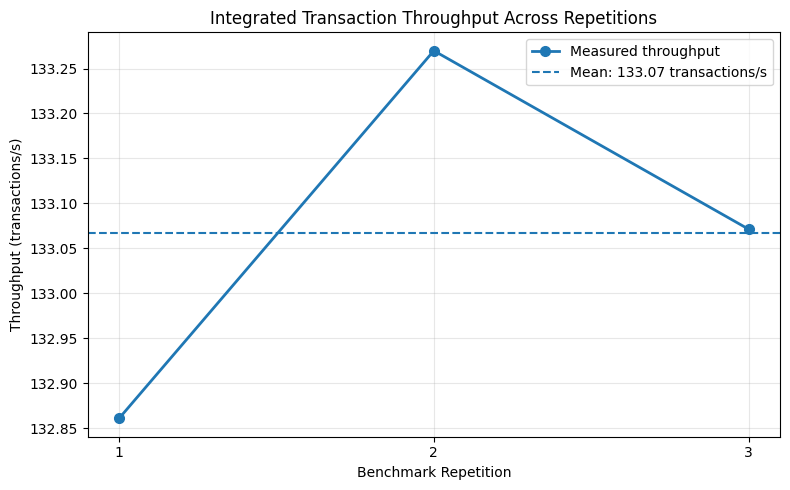

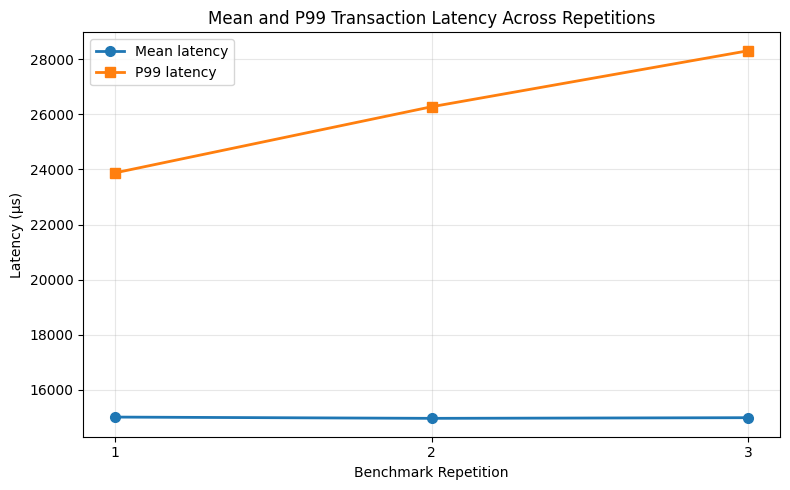

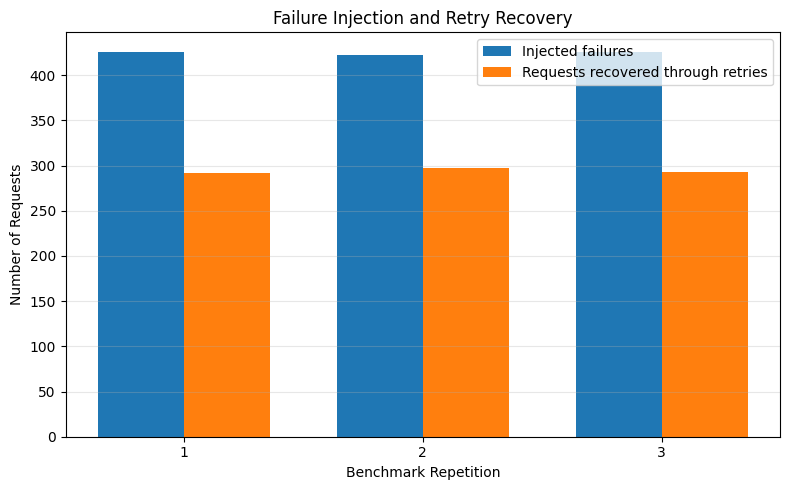

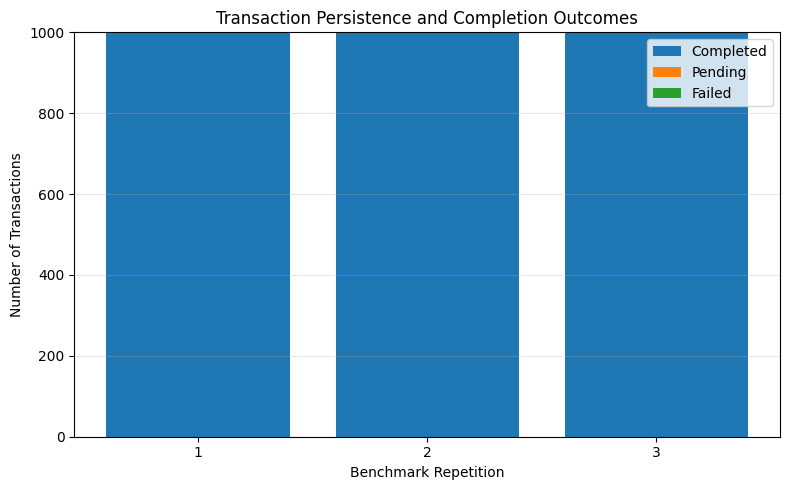


FIGURE GENERATION AND FILE VERIFICATION
Figure_1_Integrated_Throughput.png                         178,018 bytes PASS
Figure_2_Transaction_Latency.png                           121,584 bytes PASS
Figure_3_Failure_Injection_Recovery.png                    105,263 bytes PASS
Figure_4_Transaction_Outcomes.png                           95,268 bytes PASS
MSC502_M1_Integrated_Benchmark_Figures.pdf                 202,009 bytes PASS
---------------------------------------------------------------------------
FINAL RESULT: 5/5 FIGURE FILES VERIFIED
Overall verification: PASS

Output directory: /content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing/figures
STEP 12A COMPLETED


In [24]:
# STEP 12A: GENERATION OF TECHNICAL REPORT FIGURES

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. PROJECT PATHS AND DATA LOADING
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing"
)

RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RAW_FILE = RESULTS_DIR / "step_11G_integrated_raw.csv"

if not RAW_FILE.exists():
    raise FileNotFoundError(
        f"Required benchmark file not found: {RAW_FILE}"
    )

df = pd.read_csv(RAW_FILE)

required_columns = [
    "repetition",
    "throughput_ops_sec",
    "mean_latency_us",
    "p99_latency_us",
    "injected_failures",
    "recovered",
    "observed_failure_rate",
    "successful",
    "database_completed",
    "database_pending",
    "database_failed"
]

missing = [
    column for column in required_columns
    if column not in df.columns
]

if missing:
    raise ValueError(
        f"Missing required benchmark columns: {missing}"
    )

if len(df) != 3:
    raise ValueError(
        f"Expected three benchmark repetitions, found {len(df)}"
    )

df = df.sort_values("repetition").reset_index(drop=True)

print("=" * 75)
print("MSC502 M1: TECHNICAL REPORT FIGURE GENERATION")
print("=" * 75)

print("\nVerified benchmark data:")
print(df[[
    "repetition",
    "throughput_ops_sec",
    "mean_latency_us",
    "p99_latency_us",
    "injected_failures",
    "recovered"
]].to_string(index=False))

# ------------------------------------------------------------
# 2. FIGURE 1: INTEGRATED TRANSACTION THROUGHPUT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    df["repetition"],
    df["throughput_ops_sec"],
    marker="o",
    linewidth=2,
    markersize=7,
    label="Measured throughput"
)

ax.axhline(
    df["throughput_ops_sec"].mean(),
    linestyle="--",
    linewidth=1.5,
    label=f'Mean: {df["throughput_ops_sec"].mean():.2f} transactions/s'
)

ax.set_title(
    "Integrated Transaction Throughput Across Repetitions"
)
ax.set_xlabel("Benchmark Repetition")
ax.set_ylabel("Throughput (transactions/s)")
ax.set_xticks(df["repetition"])
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig1 = FIGURES_DIR / "Figure_1_Integrated_Throughput.png"

fig.savefig(fig1, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 3. FIGURE 2: TRANSACTION LATENCY
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    df["repetition"],
    df["mean_latency_us"],
    marker="o",
    linewidth=2,
    markersize=7,
    label="Mean latency"
)

ax.plot(
    df["repetition"],
    df["p99_latency_us"],
    marker="s",
    linewidth=2,
    markersize=7,
    label="P99 latency"
)

ax.set_title(
    "Mean and P99 Transaction Latency Across Repetitions"
)
ax.set_xlabel("Benchmark Repetition")
ax.set_ylabel("Latency (µs)")
ax.set_xticks(df["repetition"])
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig2 = FIGURES_DIR / "Figure_2_Transaction_Latency.png"

fig.savefig(fig2, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 4. FIGURE 3: FAILURE INJECTION AND RETRY RECOVERY
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

x = df["repetition"]

ax.bar(
    x - 0.18,
    df["injected_failures"],
    width=0.36,
    label="Injected failures"
)

ax.bar(
    x + 0.18,
    df["recovered"],
    width=0.36,
    label="Requests recovered through retries"
)

ax.set_title(
    "Failure Injection and Retry Recovery"
)
ax.set_xlabel("Benchmark Repetition")
ax.set_ylabel("Number of Requests")
ax.set_xticks(x)
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()

fig3 = FIGURES_DIR / "Figure_3_Failure_Injection_Recovery.png"

fig.savefig(fig3, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. FIGURE 4: DURABLE TRANSACTION OUTCOMES
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    df["repetition"],
    df["database_completed"],
    label="Completed"
)

ax.bar(
    df["repetition"],
    df["database_pending"],
    bottom=df["database_completed"],
    label="Pending"
)

ax.bar(
    df["repetition"],
    df["database_failed"],
    bottom=(
        df["database_completed"]
        + df["database_pending"]
    ),
    label="Failed"
)

ax.set_title(
    "Transaction Persistence and Completion Outcomes"
)
ax.set_xlabel("Benchmark Repetition")
ax.set_ylabel("Number of Transactions")
ax.set_xticks(df["repetition"])
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()

fig4 = FIGURES_DIR / "Figure_4_Transaction_Outcomes.png"

fig.savefig(fig4, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. EXPORT ALL FIGURES INTO A SINGLE PDF
# ------------------------------------------------------------

from matplotlib.backends.backend_pdf import PdfPages

pdf_path = FIGURES_DIR / "MSC502_M1_Integrated_Benchmark_Figures.pdf"

with PdfPages(pdf_path) as pdf:

    for figure_path in [fig1, fig2, fig3, fig4]:

        image = plt.imread(figure_path)

        fig, ax = plt.subplots(figsize=(11, 7))
        ax.imshow(image)
        ax.axis("off")

        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)

# ------------------------------------------------------------
# 7. VERIFY GENERATED FIGURES
# ------------------------------------------------------------

figure_files = [
    fig1,
    fig2,
    fig3,
    fig4,
    pdf_path
]

print("\n" + "=" * 75)
print("FIGURE GENERATION AND FILE VERIFICATION")
print("=" * 75)

all_valid = True

for file_path in figure_files:

    exists = file_path.exists()
    size = file_path.stat().st_size if exists else 0

    valid = exists and size > 0
    all_valid = all_valid and valid

    print(
        f"{file_path.name:<55} "
        f"{size:>10,} bytes "
        f"{'PASS' if valid else 'FAIL'}"
    )

print("-" * 75)
print(
    f"FINAL RESULT: "
    f"{sum(f.exists() and f.stat().st_size > 0 for f in figure_files)}"
    f"/{len(figure_files)} FIGURE FILES VERIFIED"
)

print("Overall verification:", "PASS" if all_valid else "FAIL")

print("\nOutput directory:", FIGURES_DIR)

print("=" * 75)
print("STEP 12A COMPLETED")
print("=" * 75)

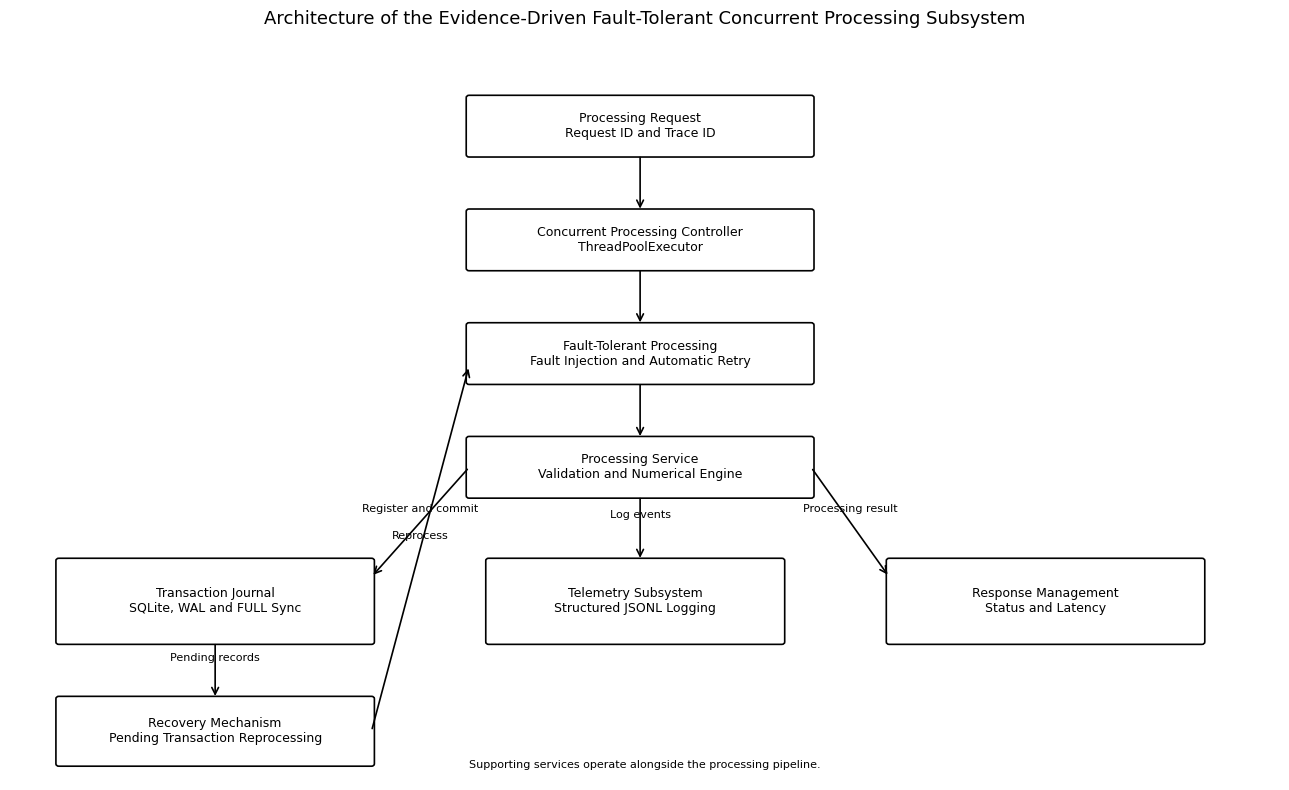

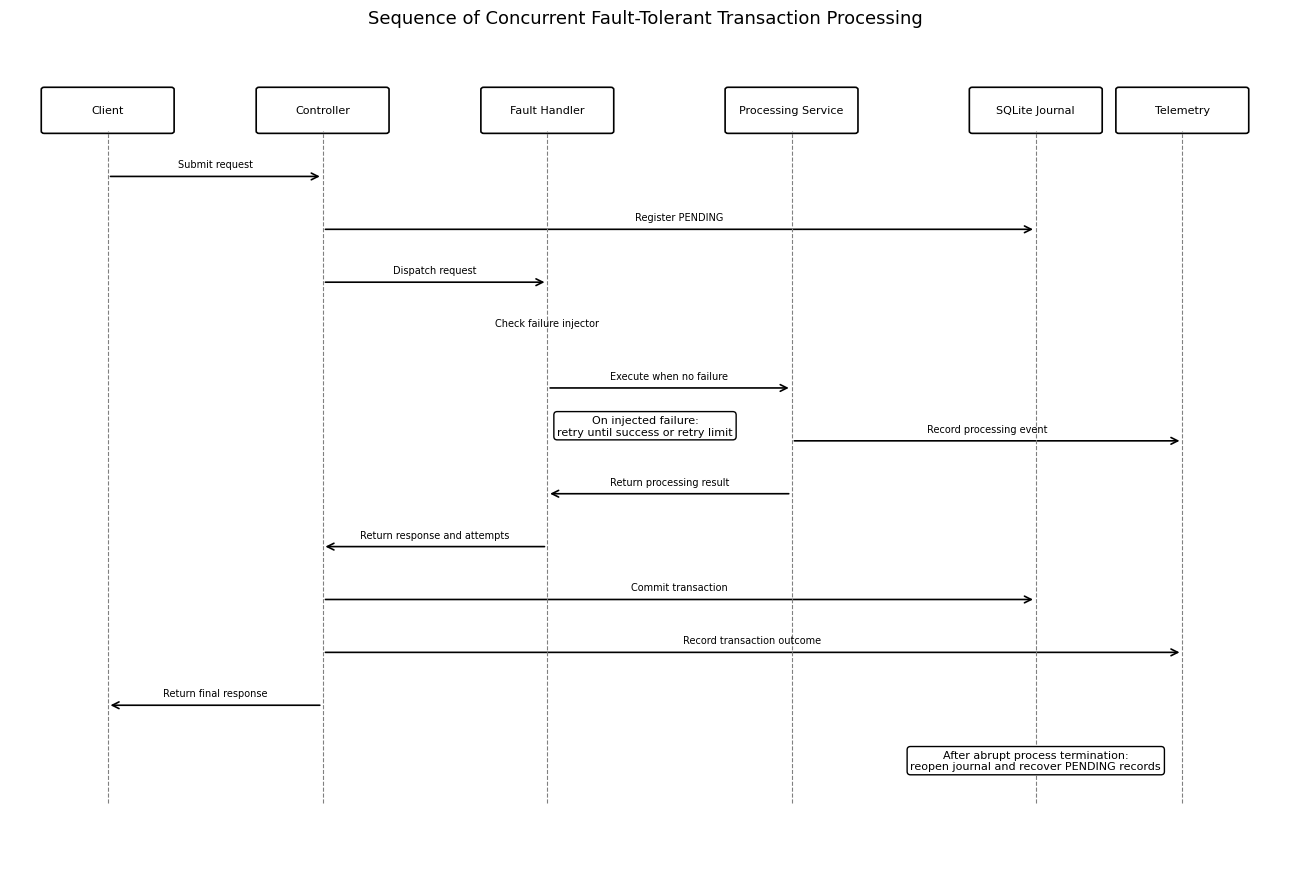


STEP 12B: DIAGRAM FILE VERIFICATION
Figure_5_System_Architecture.png                           311,684 bytes PASS
Figure_6_Processing_Sequence.png                           231,513 bytes PASS
MSC502_M1_Architecture_and_Sequence.pdf                     59,774 bytes PASS
---------------------------------------------------------------------------
FINAL RESULT: 3/3 FILES VERIFIED
Overall verification: PASS


In [25]:
# STEP 12B: SYSTEM ARCHITECTURE AND PROCESSING SEQUENCE DIAGRAMS

from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.backends.backend_pdf import PdfPages

PROJECT_ROOT = Path(
    "/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing"
)

FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# COMMON DRAWING FUNCTIONS
# ------------------------------------------------------------

def draw_box(ax, x, y, width, height, text, fontsize=9):
    box = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0.03",
        linewidth=1.2,
        edgecolor="black",
        facecolor="white"
    )

    ax.add_patch(box)

    ax.text(
        x + width / 2,
        y + height / 2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
        wrap=True
    )


def draw_arrow(ax, start, end, label=None, fontsize=8):
    arrow = FancyArrowPatch(
        start,
        end,
        arrowstyle="->",
        mutation_scale=12,
        linewidth=1.2,
        color="black"
    )

    ax.add_patch(arrow)

    if label:
        midpoint = (
            (start[0] + end[0]) / 2,
            (start[1] + end[1]) / 2
        )

        ax.text(
            midpoint[0],
            midpoint[1] + 0.12,
            label,
            ha="center",
            fontsize=fontsize
        )


# ------------------------------------------------------------
# FIGURE 5: SYSTEM ARCHITECTURE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 8))

ax.set_xlim(0, 13)
ax.set_ylim(0, 9)
ax.axis("off")

ax.set_title(
    "Architecture of the Evidence-Driven Fault-Tolerant "
    "Concurrent Processing Subsystem",
    fontsize=13,
    pad=18
)

# Request and control layer
draw_box(ax, 4.7, 7.7, 3.5, 0.7, "Processing Request\nRequest ID and Trace ID")

# Concurrent execution
draw_box(ax, 4.7, 6.3, 3.5, 0.7, "Concurrent Processing Controller\nThreadPoolExecutor")

# Fault tolerance
draw_box(ax, 4.7, 4.9, 3.5, 0.7, "Fault-Tolerant Processing\nFault Injection and Automatic Retry")

# Processing pipeline
draw_box(ax, 4.7, 3.5, 3.5, 0.7, "Processing Service\nValidation and Numerical Engine")

# Supporting services
draw_box(ax, 0.5, 1.7, 3.2, 1.0, "Transaction Journal\nSQLite, WAL and FULL Sync")

draw_box(ax, 4.9, 1.7, 3.0, 1.0, "Telemetry Subsystem\nStructured JSONL Logging")

draw_box(ax, 9.0, 1.7, 3.2, 1.0, "Response Management\nStatus and Latency")

# Recovery
draw_box(ax, 0.5, 0.2, 3.2, 0.8, "Recovery Mechanism\nPending Transaction Reprocessing")

# Main processing flow
draw_arrow(ax, (6.45, 7.7), (6.45, 7.0))
draw_arrow(ax, (6.45, 6.3), (6.45, 5.6))
draw_arrow(ax, (6.45, 4.9), (6.45, 4.2))

# Supporting connections
draw_arrow(ax, (4.7, 3.85), (3.7, 2.5), "Register and commit")
draw_arrow(ax, (6.45, 3.5), (6.45, 2.7), "Log events")
draw_arrow(ax, (8.2, 3.85), (9.0, 2.5), "Processing result")

# Recovery connections
draw_arrow(ax, (2.1, 1.7), (2.1, 1.0), "Pending records")
draw_arrow(ax, (3.7, 0.6), (4.7, 5.1), "Reprocess", fontsize=8)

ax.text(
    6.5,
    0.15,
    "Supporting services operate alongside the processing pipeline.",
    ha="center",
    fontsize=8
)

fig.tight_layout()

architecture_path = (
    FIGURES_DIR / "Figure_5_System_Architecture.png"
)

fig.savefig(
    architecture_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# FIGURE 6: PROCESSING SEQUENCE DIAGRAM
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 9))

ax.set_xlim(0, 13)
ax.set_ylim(0, 11)
ax.axis("off")

ax.set_title(
    "Sequence of Concurrent Fault-Tolerant Transaction Processing",
    fontsize=13,
    pad=18
)

participants = [
    ("Client", 1.0),
    ("Controller", 3.2),
    ("Fault Handler", 5.5),
    ("Processing Service", 8.0),
    ("SQLite Journal", 10.5),
    ("Telemetry", 12.0)
]

# Participant labels and lifelines
for name, x in participants:

    draw_box(ax, x - 0.65, 9.9, 1.3, 0.55, name, fontsize=8)

    ax.plot(
        [x, x],
        [1.0, 9.9],
        linestyle="--",
        linewidth=0.8,
        color="gray"
    )

# Sequence messages
messages = [
    (9.3, 1.0, 3.2, "Submit request"),
    (8.6, 3.2, 10.5, "Register PENDING"),
    (7.9, 3.2, 5.5, "Dispatch request"),
    (7.2, 5.5, 5.5, "Check failure injector"),
    (6.5, 5.5, 8.0, "Execute when no failure"),
    (5.8, 8.0, 12.0, "Record processing event"),
    (5.1, 8.0, 5.5, "Return processing result"),
    (4.4, 5.5, 3.2, "Return response and attempts"),
    (3.7, 3.2, 10.5, "Commit transaction"),
    (3.0, 3.2, 12.0, "Record transaction outcome"),
    (2.3, 3.2, 1.0, "Return final response")
]

for y, source_x, target_x, label in messages:

    draw_arrow(
        ax,
        (source_x, y),
        (target_x, y),
        label,
        fontsize=7
    )

# Retry annotation
ax.text(
    6.5,
    6.0,
    "On injected failure:\nretry until success or retry limit",
    ha="center",
    va="center",
    fontsize=8,
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        edgecolor="black"
    )
)

# Recovery annotation
ax.text(
    10.5,
    1.45,
    "After abrupt process termination:\nreopen journal and recover PENDING records",
    ha="center",
    fontsize=8,
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        edgecolor="black"
    )
)

fig.tight_layout()

sequence_path = (
    FIGURES_DIR / "Figure_6_Processing_Sequence.png"
)

fig.savefig(
    sequence_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# EXPORT BOTH DIAGRAMS TO PDF
# ------------------------------------------------------------

diagram_pdf = (
    FIGURES_DIR / "MSC502_M1_Architecture_and_Sequence.pdf"
)

with PdfPages(diagram_pdf) as pdf:

    for path in [architecture_path, sequence_path]:

        image = plt.imread(path)

        fig, ax = plt.subplots(figsize=(13, 8))
        ax.imshow(image)
        ax.axis("off")

        pdf.savefig(fig, bbox_inches="tight")
        plt.close(fig)


# ------------------------------------------------------------
# VERIFY GENERATED FILES
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 12B: DIAGRAM FILE VERIFICATION")
print("=" * 75)

files = [
    architecture_path,
    sequence_path,
    diagram_pdf
]

passed = 0

for path in files:

    valid = path.exists() and path.stat().st_size > 0

    if valid:
        passed += 1

    print(
        f"{path.name:<55} "
        f"{path.stat().st_size if path.exists() else 0:>10,} bytes "
        f"{'PASS' if valid else 'FAIL'}"
    )

print("-" * 75)
print(f"FINAL RESULT: {passed}/3 FILES VERIFIED")
print("Overall verification:", "PASS" if passed == 3 else "FAIL")
print("=" * 75)

In [26]:
# STEP 12C: CONSOLIDATE ALL SIX REPORT FIGURES

from pathlib import Path
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(
    "/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing"
)

FIGURES_DIR = PROJECT_ROOT / "figures"

figure_names = [
    "Figure_1_Integrated_Throughput.png",
    "Figure_2_Transaction_Latency.png",
    "Figure_3_Failure_Injection_Recovery.png",
    "Figure_4_Transaction_Outcomes.png",
    "Figure_5_System_Architecture.png",
    "Figure_6_Processing_Sequence.png"
]

print("=" * 75)
print("MSC502 M1: CONSOLIDATED REPORT FIGURE VALIDATION")
print("=" * 75)

# Verify all source figures
missing_files = []

for name in figure_names:
    path = FIGURES_DIR / name

    if not path.exists() or path.stat().st_size == 0:
        missing_files.append(name)
    else:
        print(f"{name:<55} PASS")

if missing_files:
    raise FileNotFoundError(
        f"Missing or empty figure files: {missing_files}"
    )

# Create consolidated PDF
output_pdf = (
    FIGURES_DIR / "MSC502_M1_Complete_Report_Figures.pdf"
)

with PdfPages(output_pdf) as pdf:

    for index, name in enumerate(figure_names, start=1):

        image_path = FIGURES_DIR / name
        image = plt.imread(image_path)

        fig, ax = plt.subplots(figsize=(11.69, 8.27))

        ax.imshow(image)
        ax.axis("off")

        fig.suptitle(
            f"MSC502 M1: Technical Report Figure {index}",
            fontsize=12,
            y=0.98
        )

        fig.tight_layout()

        pdf.savefig(
            fig,
            bbox_inches="tight"
        )

        plt.close(fig)

# Verify final PDF
print("\n" + "=" * 75)
print("CONSOLIDATED PDF VERIFICATION")
print("=" * 75)

valid = (
    output_pdf.exists()
    and output_pdf.stat().st_size > 0
)

print("Output file:", output_pdf.name)
print(
    "File size:",
    f"{output_pdf.stat().st_size:,} bytes" if valid else "0 bytes"
)
print("Verification:", "PASS" if valid else "FAIL")

print("\nFigures included:", len(figure_names))
print("Overall result:", "PASS" if valid else "FAIL")

print("=" * 75)
print("STEP 12C COMPLETED" if valid else "STEP 12C FAILED")
print("=" * 75)

MSC502 M1: CONSOLIDATED REPORT FIGURE VALIDATION
Figure_1_Integrated_Throughput.png                      PASS
Figure_2_Transaction_Latency.png                        PASS
Figure_3_Failure_Injection_Recovery.png                 PASS
Figure_4_Transaction_Outcomes.png                       PASS
Figure_5_System_Architecture.png                        PASS
Figure_6_Processing_Sequence.png                        PASS

CONSOLIDATED PDF VERIFICATION
Output file: MSC502_M1_Complete_Report_Figures.pdf
File size: 369,724 bytes
Verification: PASS

Figures included: 6
Overall result: PASS
STEP 12C COMPLETED


In [27]:
# STEP 13A: FINAL INTEGRATED PROJECT VALIDATION

from pathlib import Path
import subprocess
import sys
import pandas as pd
import sqlite3
import json

PROJECT_ROOT = Path(
    "/content/MSC502-M1-Evidence-Driven-Fault-Tolerant-Processing"
)

SRC = PROJECT_ROOT / "src"
TESTS = PROJECT_ROOT / "tests"
RESULTS = PROJECT_ROOT / "results"
FIGURES = PROJECT_ROOT / "figures"
DATA = PROJECT_ROOT / "data"

checks = []

def record_check(name, passed, detail=""):
    checks.append({
        "check": name,
        "status": "PASS" if passed else "FAIL",
        "detail": str(detail)
    })
    print(
        f"{name:<48} "
        f"{'PASS' if passed else 'FAIL':<8} "
        f"{detail}"
    )

print("=" * 85)
print("MSC502 M1: FINAL INTEGRATED SYSTEM VALIDATION")
print("=" * 85)

# ------------------------------------------------------------
# 1. SOURCE MODULE VERIFICATION
# ------------------------------------------------------------

print("\n1. SOURCE MODULE VERIFICATION")
print("-" * 85)

required_modules = [
    "config.py",
    "models.py",
    "validator.py",
    "engine.py",
    "telemetry.py",
    "processor.py",
    "concurrency.py",
    "fault_injector.py",
    "fault_tolerance.py",
    "transaction_manager.py"
]

for module in required_modules:
    path = SRC / module
    record_check(
        f"Source module: {module}",
        path.exists() and path.stat().st_size > 0,
        f"{path.stat().st_size:,} bytes" if path.exists() else "Missing"
    )

# ------------------------------------------------------------
# 2. AUTOMATED TEST SUITE
# ------------------------------------------------------------

print("\n2. AUTOMATED TEST SUITE")
print("-" * 85)

test_command = [
    sys.executable,
    "-m",
    "pytest",
    str(TESTS),
    "-v",
    "--tb=short"
]

test_result = subprocess.run(
    test_command,
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True
)

print(test_result.stdout)

if test_result.stderr:
    print("TEST STDERR:")
    print(test_result.stderr)

test_passed = test_result.returncode == 0

record_check(
    "Automated pytest suite",
    test_passed,
    f"Exit code: {test_result.returncode}"
)

# ------------------------------------------------------------
# 3. BENCHMARK DATASET VERIFICATION
# ------------------------------------------------------------

print("\n3. BENCHMARK DATASET VERIFICATION")
print("-" * 85)

benchmark_files = [
    "step_9_benchmark_raw.csv",
    "step_9_benchmark_summary.csv",
    "step_10_fault_tolerance_raw.csv",
    "step_10_fault_tolerance_summary.csv",
    "step_11G_integrated_raw.csv",
    "step_11G_integrated_summary.csv"
]

for filename in benchmark_files:

    path = RESULTS / filename

    valid = path.exists() and path.stat().st_size > 0

    if valid:
        try:
            data = pd.read_csv(path)
            valid = len(data) > 0
            detail = (
                f"{len(data):,} rows, "
                f"{len(data.columns)} columns"
            )
        except Exception as exc:
            valid = False
            detail = str(exc)
    else:
        detail = "Missing or empty"

    record_check(
        f"Dataset: {filename}",
        valid,
        detail
    )

# ------------------------------------------------------------
# 4. INTEGRATED BENCHMARK CONSISTENCY
# ------------------------------------------------------------

print("\n4. INTEGRATED BENCHMARK CONSISTENCY")
print("-" * 85)

integrated_file = RESULTS / "step_11G_integrated_raw.csv"

if integrated_file.exists():

    integrated = pd.read_csv(integrated_file)

    expected_columns = [
        "throughput_ops_sec",
        "mean_latency_us",
        "p99_latency_us"
    ]

    columns_valid = all(
        column in integrated.columns
        for column in expected_columns
    )

    record_check(
        "Integrated benchmark columns",
        columns_valid,
        ", ".join(expected_columns)
    )

    if columns_valid:

        numeric_valid = (
            integrated[expected_columns]
            .apply(pd.to_numeric, errors="coerce")
            .notna()
            .all()
            .all()
        )

        record_check(
            "Integrated benchmark numeric values",
            numeric_valid,
            "Throughput and latency values are numeric"
        )

        positive_valid = (
            (integrated["throughput_ops_sec"] > 0).all()
            and (integrated["mean_latency_us"] >= 0).all()
            and (integrated["p99_latency_us"] >= 0).all()
        )

        record_check(
            "Integrated benchmark value ranges",
            positive_valid,
            "Positive throughput and non-negative latency"
        )

    record_check(
        "Three benchmark repetitions",
        len(integrated) == 3,
        f"Rows found: {len(integrated)}"
    )

else:
    record_check(
        "Integrated benchmark consistency",
        False,
        "Integrated raw CSV missing"
    )

# ------------------------------------------------------------
# 5. SQLITE DATABASE INTEGRITY
# ------------------------------------------------------------

print("\n5. SQLITE DATABASE INTEGRITY")
print("-" * 85)

database_files = [
    "step_11_transaction_validation.db",
    "step_11_crash_recovery.db"
]

for filename in database_files:

    path = DATA / filename

    if not path.exists():
        record_check(
            f"Database: {filename}",
            False,
            "Database file missing"
        )
        continue

    try:
        connection = sqlite3.connect(str(path))

        integrity = connection.execute(
            "PRAGMA integrity_check"
        ).fetchone()[0]

        tables = connection.execute(
            """
            SELECT name
            FROM sqlite_master
            WHERE type='table' AND name='transactions'
            """
        ).fetchall()

        record_count = 0

        if tables:
            record_count = connection.execute(
                "SELECT COUNT(*) FROM transactions"
            ).fetchone()[0]

        connection.close()

        valid = integrity == "ok" and len(tables) == 1

        record_check(
            f"Database: {filename}",
            valid,
            f"Integrity: {integrity}; transactions: {record_count}"
        )

    except Exception as exc:

        record_check(
            f"Database: {filename}",
            False,
            str(exc)
        )

# ------------------------------------------------------------
# 6. REPORT FIGURE VERIFICATION
# ------------------------------------------------------------

print("\n6. REPORT FIGURE VERIFICATION")
print("-" * 85)

required_figures = [
    "Figure_1_Integrated_Throughput.png",
    "Figure_2_Transaction_Latency.png",
    "Figure_3_Failure_Injection_Recovery.png",
    "Figure_4_Transaction_Outcomes.png",
    "Figure_5_System_Architecture.png",
    "Figure_6_Processing_Sequence.png",
    "MSC502_M1_Integrated_Benchmark_Figures.pdf",
    "MSC502_M1_Architecture_and_Sequence.pdf",
    "MSC502_M1_Complete_Report_Figures.pdf"
]

for filename in required_figures:

    path = FIGURES / filename

    valid = path.exists() and path.stat().st_size > 0

    record_check(
        f"Report artefact: {filename}",
        valid,
        f"{path.stat().st_size:,} bytes"
        if path.exists() else "Missing"
    )

# ------------------------------------------------------------
# 7. FINAL VALIDATION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("FINAL VALIDATION SUMMARY")
print("=" * 85)

passed = sum(
    item["status"] == "PASS"
    for item in checks
)

failed = len(checks) - passed

print(f"Total checks : {len(checks)}")
print(f"Passed       : {passed}")
print(f"Failed       : {failed}")

print("-" * 85)

if failed == 0:
    print("FINAL RESULT: ALL VALIDATION CHECKS PASSED")
else:
    print("FINAL RESULT: VALIDATION REQUIRES ATTENTION")

print("=" * 85)

# Save the validation evidence
validation_df = pd.DataFrame(checks)

validation_file = (
    RESULTS / "step_13A_final_validation.csv"
)

validation_df.to_csv(validation_file, index=False)

print("\nValidation evidence saved:")
print(validation_file)
print(f"File size: {validation_file.stat().st_size:,} bytes")

MSC502 M1: FINAL INTEGRATED SYSTEM VALIDATION

1. SOURCE MODULE VERIFICATION
-------------------------------------------------------------------------------------
Source module: config.py                         PASS     627 bytes
Source module: models.py                         PASS     702 bytes
Source module: validator.py                      PASS     755 bytes
Source module: engine.py                         PASS     733 bytes
Source module: telemetry.py                      PASS     1,216 bytes
Source module: processor.py                      PASS     1,853 bytes
Source module: concurrency.py                    PASS     711 bytes
Source module: fault_injector.py                 PASS     1,223 bytes
Source module: fault_tolerance.py                PASS     1,848 bytes
Source module: transaction_manager.py            PASS     6,087 bytes

2. AUTOMATED TEST SUITE
-------------------------------------------------------------------------------------
============================= test s